# Promo Effectiveness: Incremental Sales Analysis

## 1. Data Understanding and Validation

**Business question:** Do retail campaigns generate
incremental sales, or would households have purchased anyway?

**Dataset:** dunnhumby Complete Journey

**Completed checks:**
- 30 campaigns identified.
- 2,318 coupon redemptions.
- 0 redemptions without campaign assignment.
- PostgreSQL reporting schema confirmed as `dbt_dev`.

**Important limitation:** Campaign assignment does not
prove that a household actually saw a promotion.

**Data-source caveat:** Figures use dunnhumby's public sample dataset, not any retailer's campaign data.

In [1]:
import sys
import importlib.util

print("Python:", sys.executable)

for package in ["ipykernel", "pandas", "sqlalchemy", "psycopg2", "psycopg", "yaml", "dotenv"]:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Missing'}")

Python: S:\venvs\retail-dbt\Scripts\python.exe
ipykernel: Installed
pandas: Installed
sqlalchemy: Installed
psycopg2: Installed
psycopg: Missing
yaml: Installed
dotenv: Installed


In [2]:
import pandas as pd
import sqlalchemy

print("Pandas:", pd.__version__)
print("SQLAlchemy:", sqlalchemy.__version__)

Pandas: 2.3.3
SQLAlchemy: 2.0.57


In [3]:
import os
import sys

expected_python = os.path.normcase(
    os.path.realpath(r"S:\venvs\retail-dbt\Scripts\python.exe")
)
actual_python = os.path.normcase(os.path.realpath(sys.executable))
print("Current Python:", sys.executable)
if actual_python != expected_python:
    raise RuntimeError("Select the retail-dbt kernel before running this notebook.")


Current Python: S:\venvs\retail-dbt\Scripts\python.exe


## Setup: read-only database connection

After restarting the kernel, run this notebook from top to bottom. This cell initializes the shared SQLAlchemy engine before any SQL query cells.


In [4]:
from pathlib import Path
import sys
import pandas as pd
from sqlalchemy import text

working_directory=Path.cwd().resolve()
project_root=next((candidate for candidate in (working_directory,*working_directory.parents)
                   if (candidate/'src'/'promo_effectiveness'/'__init__.py').is_file()),None)
if project_root is None:
    raise RuntimeError("Could not locate src/promo_effectiveness from the notebook working directory.")
source_path=str(project_root/'src')
if source_path not in sys.path:
    sys.path.insert(0,source_path)

from promo_effectiveness import (
    build_campaign_overview,
    build_campaign_windows,
    campaign26_spending_svg,
    campaign_assignment_overlap_svg,
    create_readonly_engine,
    fetch_assignment_pairs,
    fetch_campaign26_household_periods,
    fetch_campaign_dimensions,
    fetch_promotion_quality,
    fetch_redemption_events,
    load_database_config,
    save_svg,
    summarize_household_periods,
    summarize_promotion_quality,
    verify_readonly,
)

db_config=load_database_config(project_root/'secrets'/'retail-analytics.env')
engine=create_readonly_engine(db_config)
with engine.connect() as conn:
    print("Connected to:",conn.execute(text("SELECT current_database()")).scalar_one())
print("Read-only session:","on" if verify_readonly(engine) else "off")


Connected to: retail_analytics
Read-only session: on


In [5]:
import pandas as pd
from sqlalchemy import text

query = text("""
    SELECT
        table_name,
        column_name,
        data_type
    FROM information_schema.columns
    WHERE table_schema = 'raw'
      AND table_name IN (
          'campaign_desc',
          'campaign_table',
          'coupon',
          'coupon_redempt'
      )
    ORDER BY table_name, ordinal_position
""")

with engine.connect() as conn:
    display(pd.read_sql(query, conn))

,table_name,column_name,data_type
0,campaign_desc,description,text
1,campaign_desc,campaign,integer
2,campaign_desc,start_day,integer
3,campaign_desc,end_day,integer
4,campaign_table,description,text
5,campaign_table,household_key,integer
6,campaign_table,campaign,integer
7,coupon,coupon_upc,bigint
8,coupon,product_id,integer
9,coupon,campaign,integer


In [6]:
query = text("""
    SELECT 'campaign_desc' AS table_name, COUNT(*) AS rows
    FROM raw.campaign_desc

    UNION ALL
    SELECT 'campaign_table', COUNT(*)
    FROM raw.campaign_table

    UNION ALL
    SELECT 'coupon', COUNT(*)
    FROM raw.coupon

    UNION ALL
    SELECT 'coupon_redempt', COUNT(*)
    FROM raw.coupon_redempt
""")

with engine.connect() as conn:
    display(pd.read_sql(query, conn))

,table_name,rows
0,campaign_desc,30
1,campaign_table,7208
2,coupon,124548
3,coupon_redempt,2318


In [7]:
import pandas as pd
from sqlalchemy import text

query = text("""
SELECT
    table_schema,
    table_name,
    column_name,
    data_type
FROM information_schema.columns
WHERE
    (table_schema = 'raw'
     AND table_name = 'causal_data')
    OR
    (table_schema = 'dbt_dev'
     AND table_name = 'fct_promotion_week')
ORDER BY table_schema, table_name, ordinal_position
""")

with engine.connect() as conn:
    display(pd.read_sql(query, conn))

,table_schema,table_name,column_name,data_type
0,dbt_dev,fct_promotion_week,product_id,integer
1,dbt_dev,fct_promotion_week,store_id,integer
2,dbt_dev,fct_promotion_week,week_no,integer
3,dbt_dev,fct_promotion_week,source_state_count,bigint
4,dbt_dev,fct_promotion_week,display_state_count,bigint
5,dbt_dev,fct_promotion_week,mailer_state_count,bigint
6,dbt_dev,fct_promotion_week,has_display,boolean
7,dbt_dev,fct_promotion_week,has_mailer,boolean
8,raw,causal_data,product_id,integer
9,raw,causal_data,store_id,integer


## Campaign count validation


In [8]:
from sqlalchemy import text

with engine.connect() as conn:
    campaign_count = conn.execute(
        text("SELECT COUNT(*) FROM dbt_dev.dim_campaign")
    ).scalar_one()

if campaign_count != 30:
    raise AssertionError(f"Expected 30 campaigns, found {campaign_count}")

print(f"Read-only connection verified: {campaign_count} campaigns in dbt_dev.dim_campaign")


Read-only connection verified: 30 campaigns in dbt_dev.dim_campaign


## Coupon redemption targeting validation


In [9]:
from sqlalchemy import text

validation_query = text("""
    SELECT
        COUNT(*) AS redemption_count,
        COUNT(*) FILTER (
            WHERE NOT EXISTS (
                SELECT 1
                FROM raw.campaign_table AS assigned
                WHERE assigned.household_key = redemption.household_key
                  AND assigned.campaign = redemption.campaign
            )
        ) AS unassigned_redemption_count
    FROM raw.coupon_redempt AS redemption
""")

with engine.connect() as conn:
    redemption_count, unassigned_count = conn.execute(validation_query).one()

if redemption_count != 2318:
    raise AssertionError(f"Expected 2,318 redemptions, found {redemption_count}")
if unassigned_count != 0:
    raise AssertionError(f"Expected 0 unassigned redemptions, found {unassigned_count}")

print(f"Coupon redemptions: {redemption_count:,}")
print(f"Redemptions not assigned to matching campaign: {unassigned_count}")
print("Targeting validation passed.")


Coupon redemptions: 2,318
Redemptions not assigned to matching campaign: 0
Targeting validation passed.


## Transaction data coverage (read-only)


In [10]:
import pandas as pd
from sqlalchemy import text

query = text("""
    SELECT
        MIN(day) AS first_transaction_day,
        MAX(day) AS last_transaction_day,
        COUNT(DISTINCT household_key) AS total_households,
        COUNT(*) AS transaction_lines
    FROM raw.transaction_data
""")

coverage = pd.read_sql_query(query, engine)
display(coverage)


,first_transaction_day,last_transaction_day,total_households,transaction_lines
0,1,711,2500,2595732


In [11]:

query = """
SELECT
    c.campaign,
    c.description AS campaign_type,
    c.start_day,
    c.end_day,
    c.end_day - c.start_day + 1 AS duration_days,
    COUNT(DISTINCT a.household_key) AS assigned_households,
    CASE
        WHEN c.start_day >= 29
         AND c.end_day <= 683
        THEN 'Eligible'
        ELSE 'Insufficient coverage'
    END AS coverage_status
FROM raw.campaign_desc AS c
LEFT JOIN raw.campaign_table AS a
    ON c.campaign = a.campaign
GROUP BY
    c.campaign,
    c.description,
    c.start_day,
    c.end_day
ORDER BY
    assigned_households DESC,
    c.campaign;
"""

campaign_summary = pd.read_sql_query(query, engine)
display(campaign_summary)


,campaign,campaign_type,start_day,end_day,duration_days,assigned_households,coverage_status
0,18,TypeA,587,642,56,1133,Eligible
1,13,TypeA,504,551,48,1077,Eligible
2,8,TypeA,412,460,49,1076,Eligible
3,30,TypeA,323,369,47,361,Eligible
4,26,TypeA,224,264,41,332,Eligible
5,22,TypeB,624,656,33,276,Eligible
6,20,TypeC,615,685,71,244,Insufficient coverage
7,14,TypeC,531,596,66,224,Eligible
8,11,TypeB,477,523,47,214,Eligible
9,17,TypeB,575,607,33,202,Eligible


## Assignment integrity and overlap

The 28-day pre and post windows are inclusive. Date overlap is reported separately from household co-assignment. All assignment pairs are deduplicated before counting.


In [12]:
import pandas as pd
from sqlalchemy import text

assignment_integrity_query = text("""
    WITH pair_counts AS (
        SELECT household_key, campaign_id, COUNT(*) AS row_count
        FROM dbt_dev.bridge_household_campaign
        GROUP BY household_key, campaign_id
    )
    SELECT
        COALESCE(SUM(row_count), 0)::bigint AS assignment_rows,
        COUNT(*)::bigint AS unique_household_campaign_pairs,
        COALESCE(SUM(row_count - 1), 0)::bigint AS duplicate_assignment_rows,
        COUNT(*) FILTER (WHERE row_count > 1)::bigint AS duplicated_pairs
    FROM pair_counts
""")

with engine.connect() as conn:
    assignment_integrity = pd.read_sql_query(assignment_integrity_query, conn)

overlap_query = text("""
    WITH candidates AS (
        SELECT campaign_id, campaign_type, start_day, end_day
        FROM dbt_dev.dim_campaign
        WHERE campaign_id IN (8, 13, 11, 14)
    ),
    windows AS (
        SELECT campaign_id, campaign_type, start_day, end_day,
               'pre'::text AS phase,
               start_day - 28 AS window_start, start_day - 1 AS window_end
        FROM candidates
        UNION ALL
        SELECT campaign_id, campaign_type, start_day, end_day,
               'during'::text, start_day, end_day
        FROM candidates
        UNION ALL
        SELECT campaign_id, campaign_type, start_day, end_day,
               'post'::text, end_day + 1, end_day + 28
        FROM candidates
        UNION ALL
        SELECT campaign_id, campaign_type, start_day, end_day,
               'full_period'::text, start_day - 28, end_day + 28
        FROM candidates
    ),
    assignment_pairs AS (
        SELECT DISTINCT household_key, campaign_id
        FROM dbt_dev.bridge_household_campaign
    ),
    households AS (
        SELECT DISTINCT household_key
        FROM dbt_dev.dim_household
    ),
    overlapping_campaigns AS (
        SELECT
            w.campaign_id AS candidate_id,
            w.phase,
            other.campaign_id AS other_campaign_id
        FROM windows AS w
        JOIN dbt_dev.dim_campaign AS other
          ON other.campaign_id <> w.campaign_id
         AND other.start_day <= w.window_end
         AND other.end_day >= w.window_start
    ),
    date_overlap_summary AS (
        SELECT
            w.campaign_id,
            w.phase,
            w.campaign_type,
            w.start_day AS campaign_start_day,
            w.end_day AS campaign_end_day,
            w.window_start,
            w.window_end,
            COUNT(DISTINCT o.other_campaign_id) AS overlapping_campaign_count,
            COALESCE(
                STRING_AGG(
                    DISTINCT o.other_campaign_id::text,
                    ', ' ORDER BY o.other_campaign_id::text
                ),
                'none'
            ) AS overlapping_campaign_ids
        FROM windows AS w
        LEFT JOIN overlapping_campaigns AS o
          ON o.candidate_id = w.campaign_id
         AND o.phase = w.phase
        GROUP BY
            w.campaign_id, w.phase, w.campaign_type,
            w.start_day, w.end_day, w.window_start, w.window_end
    ),
    treatment_sizes AS (
        SELECT c.campaign_id, COUNT(DISTINCT a.household_key) AS treatment_households
        FROM candidates AS c
        LEFT JOIN assignment_pairs AS a ON a.campaign_id = c.campaign_id
        GROUP BY c.campaign_id
    ),
    comparison_sizes AS (
        SELECT
            c.campaign_id,
            COUNT(*) FILTER (WHERE a.household_key IS NULL) AS potential_comparison_households
        FROM candidates AS c
        CROSS JOIN households AS h
        LEFT JOIN assignment_pairs AS a
          ON a.campaign_id = c.campaign_id
         AND a.household_key = h.household_key
        GROUP BY c.campaign_id
    ),
    treatment_overlap AS (
        SELECT
            w.campaign_id,
            w.phase,
            COUNT(DISTINCT target.household_key)
                FILTER (WHERE other_assignment.household_key IS NOT NULL)
                AS coassigned_households
        FROM windows AS w
        LEFT JOIN overlapping_campaigns AS o
          ON o.candidate_id = w.campaign_id AND o.phase = w.phase
        LEFT JOIN assignment_pairs AS target
          ON target.campaign_id = w.campaign_id
        LEFT JOIN assignment_pairs AS other_assignment
          ON other_assignment.household_key = target.household_key
         AND other_assignment.campaign_id = o.other_campaign_id
        GROUP BY w.campaign_id, w.phase
    ),
    comparison_overlap AS (
        SELECT
            w.campaign_id,
            w.phase,
            COUNT(DISTINCT h.household_key)
                FILTER (WHERE other_assignment.household_key IS NOT NULL)
                AS assigned_elsewhere_households
        FROM windows AS w
        CROSS JOIN households AS h
        LEFT JOIN assignment_pairs AS target
          ON target.campaign_id = w.campaign_id
         AND target.household_key = h.household_key
        LEFT JOIN overlapping_campaigns AS o
          ON o.candidate_id = w.campaign_id AND o.phase = w.phase
        LEFT JOIN assignment_pairs AS other_assignment
          ON other_assignment.household_key = h.household_key
         AND other_assignment.campaign_id = o.other_campaign_id
        WHERE target.household_key IS NULL
        GROUP BY w.campaign_id, w.phase
    )
    SELECT
        d.campaign_id,
        d.campaign_type,
        d.campaign_start_day,
        d.campaign_end_day,
        d.phase,
        d.window_start,
        d.window_end,
        d.overlapping_campaign_count,
        d.overlapping_campaign_ids,
        t.treatment_households,
        COALESCE(tover.coassigned_households, 0) AS coassigned_households,
        ROUND(
            100.0 * COALESCE(tover.coassigned_households, 0)
            / NULLIF(t.treatment_households, 0),
            1
        ) AS coassigned_pct,
        c.potential_comparison_households,
        COALESCE(cover.assigned_elsewhere_households, 0)
            AS comparison_assigned_elsewhere_households,
        ROUND(
            100.0 * COALESCE(cover.assigned_elsewhere_households, 0)
            / NULLIF(c.potential_comparison_households, 0),
            1
        ) AS comparison_assigned_elsewhere_pct,
        c.potential_comparison_households
            - COALESCE(cover.assigned_elsewhere_households, 0)
            AS comparison_households_clean_this_window
    FROM date_overlap_summary AS d
    JOIN treatment_sizes AS t USING (campaign_id)
    JOIN comparison_sizes AS c USING (campaign_id)
    LEFT JOIN treatment_overlap AS tover
      ON tover.campaign_id = d.campaign_id AND tover.phase = d.phase
    LEFT JOIN comparison_overlap AS cover
      ON cover.campaign_id = d.campaign_id AND cover.phase = d.phase
    ORDER BY
        d.campaign_id,
        CASE d.phase
            WHEN 'pre' THEN 1
            WHEN 'during' THEN 2
            WHEN 'post' THEN 3
            ELSE 4
        END
""")

with engine.connect() as conn:
    overlap_summary = pd.read_sql_query(overlap_query, conn)

display(assignment_integrity)
display(overlap_summary)


,assignment_rows,unique_household_campaign_pairs,duplicate_assignment_rows,duplicated_pairs
0,7208,7208,0,0


,campaign_id,campaign_type,campaign_start_day,campaign_end_day,phase,window_start,window_end,overlapping_campaign_count,overlapping_campaign_ids,treatment_households,coassigned_households,coassigned_pct,potential_comparison_households,comparison_assigned_elsewhere_households,comparison_assigned_elsewhere_pct,comparison_households_clean_this_window
0,8,TypeA,412,460,pre,384,411,5,"3, 4, 5, 6, 7",1076,365,33.9,1424,40,2.8,1384
1,8,TypeA,412,460,during,412,460,4,"3, 6, 7, 9",1076,308,28.6,1424,65,4.6,1359
2,8,TypeA,412,460,post,461,488,4,"10, 11, 12, 9",1076,444,41.3,1424,105,7.4,1319
3,8,TypeA,412,460,full_period,384,488,9,"10, 11, 12, 3, 4, 5, 6, 7, 9",1076,596,55.4,1424,123,8.6,1301
4,11,TypeB,477,523,pre,449,476,3,"10, 8, 9",214,194,90.7,2286,941,41.2,1345
5,11,TypeB,477,523,during,477,523,3,"10, 12, 13",214,200,93.5,2286,909,39.8,1377
6,11,TypeB,477,523,post,524,551,3,"13, 14, 15",214,202,94.4,2286,895,39.2,1391
7,11,TypeB,477,523,full_period,449,551,7,"10, 12, 13, 14, 15, 8, 9",214,211,98.6,2286,1112,48.6,1174
8,13,TypeA,504,551,pre,476,503,3,"10, 11, 12",1077,389,36.1,1423,46,3.2,1377
9,13,TypeA,504,551,during,504,551,4,"11, 12, 14, 15",1077,441,40.9,1423,49,3.4,1374


## Pre-period comparison and matching feasibility

Pre-period metrics cover the 28 days immediately before each campaign. Households with no fact rows in that window are retained with zero sales and zero baskets. No matching is performed.


In [13]:
import math
import pandas as pd
from sqlalchemy import text

baseline_query = text("""
    WITH candidates AS (
        SELECT
            campaign_id,
            start_day,
            end_day,
            start_day - 28 AS pre_start_day,
            start_day - 1 AS pre_end_day
        FROM dbt_dev.dim_campaign
        WHERE campaign_id IN (8, 13, 11, 14)
    ),
    assignment_pairs AS (
        SELECT DISTINCT household_key, campaign_id
        FROM dbt_dev.bridge_household_campaign
    ),
    households AS (
        SELECT DISTINCT household_key
        FROM dbt_dev.dim_household
    ),
    overlapping_campaigns AS (
        SELECT DISTINCT
            c.campaign_id AS candidate_id,
            other.campaign_id AS other_campaign_id
        FROM candidates AS c
        JOIN dbt_dev.dim_campaign AS other
          ON other.campaign_id <> c.campaign_id
         AND other.start_day <= c.end_day + 28
         AND other.end_day >= c.start_day - 28
    ),
    cohort_members AS (
        SELECT c.campaign_id, 'treatment'::text AS cohort, a.household_key
        FROM candidates AS c
        JOIN assignment_pairs AS a ON a.campaign_id = c.campaign_id

        UNION ALL

        SELECT c.campaign_id, 'potential_comparison'::text, h.household_key
        FROM candidates AS c
        CROSS JOIN households AS h
        WHERE NOT EXISTS (
            SELECT 1
            FROM assignment_pairs AS a
            WHERE a.campaign_id = c.campaign_id
              AND a.household_key = h.household_key
        )

        UNION ALL

        SELECT c.campaign_id, 'window_clean_comparison'::text, h.household_key
        FROM candidates AS c
        CROSS JOIN households AS h
        WHERE NOT EXISTS (
            SELECT 1
            FROM assignment_pairs AS a
            WHERE a.campaign_id = c.campaign_id
              AND a.household_key = h.household_key
        )
          AND NOT EXISTS (
            SELECT 1
            FROM assignment_pairs AS a
            JOIN overlapping_campaigns AS o
              ON o.candidate_id = c.campaign_id
             AND o.other_campaign_id = a.campaign_id
            WHERE a.household_key = h.household_key
        )
    ),
    pre_sales AS (
        SELECT
            c.campaign_id,
            s.household_key,
            SUM(s.sales_value)::numeric AS pre_period_sales
        FROM candidates AS c
        JOIN dbt_dev.fct_sales AS s
          ON s.transaction_day BETWEEN c.pre_start_day AND c.pre_end_day
        GROUP BY c.campaign_id, s.household_key
    ),
    pre_shopping AS (
        SELECT
            c.campaign_id,
            b.household_key,
            COUNT(DISTINCT b.basket_id)::integer AS shopping_frequency
        FROM candidates AS c
        JOIN dbt_dev.fct_baskets AS b
          ON b.transaction_day BETWEEN c.pre_start_day AND c.pre_end_day
        GROUP BY c.campaign_id, b.household_key
    ),
    pre_household AS (
        SELECT
            COALESCE(s.campaign_id, b.campaign_id) AS campaign_id,
            COALESCE(s.household_key, b.household_key) AS household_key,
            s.pre_period_sales,
            b.shopping_frequency
        FROM pre_sales AS s
        FULL OUTER JOIN pre_shopping AS b
          ON b.campaign_id = s.campaign_id
         AND b.household_key = s.household_key
    ),
    household_metrics AS (
        SELECT
            m.campaign_id,
            m.cohort,
            m.household_key,
            COALESCE(p.pre_period_sales, 0)::numeric AS pre_period_sales,
            COALESCE(p.shopping_frequency, 0)::integer AS shopping_frequency,
            CASE WHEN p.household_key IS NULL THEN 0 ELSE 1 END::integer
                AS active_household
        FROM cohort_members AS m
        LEFT JOIN pre_household AS p
          ON p.campaign_id = m.campaign_id
         AND p.household_key = m.household_key
    )
    SELECT
        campaign_id,
        cohort,
        COUNT(*)::integer AS households,
        SUM(active_household)::integer AS active_households,
        ROUND(
            100.0 * SUM(active_household)::numeric / COUNT(*),
            1
        ) AS active_household_pct,
        ROUND(AVG(pre_period_sales), 2) AS mean_pre_sales_per_household,
        ROUND(
            (PERCENTILE_CONT(0.5) WITHIN GROUP
                (ORDER BY pre_period_sales::double precision))::numeric,
            2
        ) AS median_pre_sales_per_household,
        ROUND(AVG(shopping_frequency)::numeric, 2)
            AS mean_baskets_per_household,
        ROUND(
            (PERCENTILE_CONT(0.5) WITHIN GROUP
                (ORDER BY shopping_frequency::double precision))::numeric,
            2
        ) AS median_baskets_per_household,
        STDDEV_SAMP(pre_period_sales::double precision)
            AS sd_pre_sales_per_household,
        STDDEV_SAMP(shopping_frequency::double precision)
            AS sd_baskets_per_household,
        STDDEV_SAMP(active_household::double precision)
            AS sd_active_household
    FROM household_metrics
    GROUP BY campaign_id, cohort
    ORDER BY campaign_id, cohort
""")

with engine.connect() as conn:
    pre_period_metrics = pd.read_sql_query(baseline_query, conn)

feasibility_rows = []
for campaign_id in (8, 13, 11, 14):
    rows = pre_period_metrics[pre_period_metrics["campaign_id"] == campaign_id].set_index("cohort")
    treatment = rows.loc["treatment"]
    potential = rows.loc["potential_comparison"]
    clean = rows.loc["window_clean_comparison"]

    def standardized_difference(mean_t, sd_t, mean_c, sd_c):
        pooled_sd = math.sqrt((float(sd_t) ** 2 + float(sd_c) ** 2) / 2)
        return round((float(mean_t) - float(mean_c)) / pooled_sd, 3) if pooled_sd else None

    active_t = float(treatment["active_households"]) / int(treatment["households"])
    active_c = float(clean["active_households"]) / int(clean["households"])
    feasibility_rows.append({
        "campaign_id": campaign_id,
        "treatment_households": int(treatment["households"]),
        "potential_comparison_households": int(potential["households"]),
        "clean_comparison_households": int(clean["households"]),
        "clean_controls_per_treated": round(int(clean["households"]) / int(treatment["households"]), 2),
        "treatment_active_pre_households": int(treatment["active_households"]),
        "clean_comparison_active_pre_households": int(clean["active_households"]),
        "treatment_mean_pre_sales": round(float(treatment["mean_pre_sales_per_household"]), 2),
        "clean_comparison_mean_pre_sales": round(float(clean["mean_pre_sales_per_household"]), 2),
        "treatment_mean_pre_baskets": round(float(treatment["mean_baskets_per_household"]), 2),
        "clean_comparison_mean_pre_baskets": round(float(clean["mean_baskets_per_household"]), 2),
        "smd_pre_sales": standardized_difference(
            treatment["mean_pre_sales_per_household"],
            treatment["sd_pre_sales_per_household"],
            clean["mean_pre_sales_per_household"],
            clean["sd_pre_sales_per_household"],
        ),
        "smd_pre_baskets": standardized_difference(
            treatment["mean_baskets_per_household"],
            treatment["sd_baskets_per_household"],
            clean["mean_baskets_per_household"],
            clean["sd_baskets_per_household"],
        ),
        "smd_active_rate": standardized_difference(
            active_t,
            treatment["sd_active_household"],
            active_c,
            clean["sd_active_household"],
        ),
    })

matching_feasibility = pd.DataFrame(feasibility_rows)
display(pre_period_metrics)
display(matching_feasibility)


,campaign_id,cohort,households,active_households,active_household_pct,mean_pre_sales_per_household,median_pre_sales_per_household,mean_baskets_per_household,median_baskets_per_household,sd_pre_sales_per_household,sd_baskets_per_household,sd_active_household
0,8,potential_comparison,1424,939,65.9,76.05,26.63,2.72,1.0,135.143442,4.266800,0.474074
1,8,treatment,1076,1036,96.3,226.55,173.83,7.42,6.0,196.359845,6.684099,0.189278
2,8,window_clean_comparison,1301,822,63.2,61.50,20.77,2.32,1.0,113.896004,3.647034,0.482496
3,11,potential_comparison,2286,1826,79.9,127.07,68.20,4.50,3.0,166.018259,6.043659,0.401003
4,11,treatment,214,212,99.1,300.84,267.43,9.71,8.0,216.063423,7.706960,0.096446
5,11,window_clean_comparison,1174,786,67.0,64.19,24.00,2.27,1.0,123.470885,3.296387,0.470592
6,13,potential_comparison,1423,992,69.7,71.58,26.85,2.54,1.0,118.570179,3.750989,0.459666
7,13,treatment,1077,1039,96.5,233.26,182.80,8.02,6.0,197.990848,7.967375,0.184580
8,13,window_clean_comparison,1319,893,67.7,60.86,22.67,2.24,1.0,101.444290,3.064515,0.467789
9,14,potential_comparison,2276,1782,78.3,120.89,60.16,4.37,3.0,163.529307,5.848896,0.412326


,campaign_id,treatment_households,potential_comparison_households,clean_comparison_households,clean_controls_per_treated,treatment_active_pre_households,clean_comparison_active_pre_households,treatment_mean_pre_sales,clean_comparison_mean_pre_sales,treatment_mean_pre_baskets,clean_comparison_mean_pre_baskets,smd_pre_sales,smd_pre_baskets,smd_active_rate
0,8,1076,1424,1301,1.21,1036,822,226.55,61.50,7.42,2.32,1.028,0.947,0.903
1,13,1077,1423,1319,1.22,1039,893,233.26,60.86,8.02,2.24,1.096,0.958,0.809
2,11,214,2286,1174,5.49,212,786,300.84,64.19,9.71,2.27,1.345,1.255,0.945
3,14,224,2276,1106,4.94,214,682,312.69,47.82,9.15,1.82,1.332,1.200,0.906


## Window coverage and missing observations

Coverage checks count distinct transaction days within each pre, campaign, and post window. Unrepresented day indices may be zero-transaction days or missing source coverage; the transaction fact alone cannot distinguish those cases.


In [14]:
import pandas as pd
from sqlalchemy import text

window_coverage_query = text("""
    WITH candidates AS (
        SELECT campaign_id, start_day, end_day
        FROM dbt_dev.dim_campaign
        WHERE campaign_id IN (8, 13, 11, 14)
    ),
    windows AS (
        SELECT campaign_id, 'pre'::text AS phase,
               start_day - 28 AS window_start, start_day - 1 AS window_end
        FROM candidates
        UNION ALL
        SELECT campaign_id, 'during'::text, start_day, end_day
        FROM candidates
        UNION ALL
        SELECT campaign_id, 'post'::text, end_day + 1, end_day + 28
        FROM candidates
    )
    SELECT
        w.campaign_id,
        w.phase,
        w.window_start,
        w.window_end,
        w.window_end - w.window_start + 1 AS expected_day_indices,
        COUNT(DISTINCT s.transaction_day) AS observed_transaction_days,
        (w.window_end - w.window_start + 1)
            - COUNT(DISTINCT s.transaction_day) AS unrepresented_day_indices,
        COUNT(s.household_key)::bigint AS transaction_lines,
        COUNT(DISTINCT s.household_key) AS active_households
    FROM windows AS w
    LEFT JOIN dbt_dev.fct_sales AS s
      ON s.transaction_day BETWEEN w.window_start AND w.window_end
    GROUP BY
        w.campaign_id, w.phase, w.window_start, w.window_end
    ORDER BY
        w.campaign_id,
        CASE w.phase WHEN 'pre' THEN 1 WHEN 'during' THEN 2 ELSE 3 END
""")

transaction_field_quality_query = text("""
    SELECT
        COUNT(*)::bigint AS sales_fact_rows,
        COUNT(*) FILTER (WHERE transaction_day IS NULL)::bigint AS null_transaction_day_rows,
        COUNT(*) FILTER (WHERE household_key IS NULL)::bigint AS null_household_rows,
        COUNT(*) FILTER (WHERE basket_id IS NULL)::bigint AS null_basket_rows,
        COUNT(*) FILTER (WHERE sales_value IS NULL)::bigint AS null_sales_rows
    FROM dbt_dev.fct_sales
""")

with engine.connect() as conn:
    window_coverage = pd.read_sql_query(window_coverage_query, conn)
    transaction_field_quality = pd.read_sql_query(transaction_field_quality_query, conn)

display(window_coverage)
display(transaction_field_quality)


,campaign_id,phase,window_start,window_end,expected_day_indices,observed_transaction_days,unrepresented_day_indices,transaction_lines,active_households
0,8,pre,384,411,28,28,0,112711,1975
1,8,during,412,460,49,49,0,195221,2176
2,8,post,461,488,28,28,0,113336,2027
3,11,pre,449,476,28,28,0,112652,2038
4,11,during,477,523,47,47,0,186418,2172
5,11,post,524,551,28,28,0,110834,2009
6,13,pre,476,503,28,28,0,111895,2031
7,13,during,504,551,48,48,0,188594,2169
8,13,post,552,579,28,28,0,108508,2002
9,14,pre,503,530,28,28,0,109676,1996


,sales_fact_rows,null_transaction_day_rows,null_household_rows,null_basket_rows,null_sales_rows
0,2595732,0,0,0,0


## Candidate feasibility summary

This compact table combines assignment overlap, clean comparison-pool size, pre-period diagnostics, and window coverage. It is a screening aid, not a matched sample.


In [15]:
import pandas as pd

full_period = (
    overlap_summary.loc[overlap_summary["phase"] == "full_period"]
    .set_index("campaign_id")
)
baseline_index = pre_period_metrics.set_index(["campaign_id", "cohort"])
feasibility_index = matching_feasibility.set_index("campaign_id")
coverage_index = window_coverage.pivot(
    index="campaign_id",
    columns="phase",
    values="unrepresented_day_indices",
)

comparison_rows = []
for campaign_id in (8, 13, 11, 14):
    overlap = full_period.loc[campaign_id]
    treatment = baseline_index.loc[(campaign_id, "treatment")]
    potential = baseline_index.loc[(campaign_id, "potential_comparison")]
    clean = baseline_index.loc[(campaign_id, "window_clean_comparison")]
    match = feasibility_index.loc[campaign_id]
    coverage = coverage_index.loc[campaign_id]

    comparison_rows.append({
        "campaign_id": campaign_id,
        "type": overlap["campaign_type"],
        "campaign_days": f'{int(overlap["campaign_start_day"])}-{int(overlap["campaign_end_day"])}',
        "assigned_households": int(overlap["treatment_households"]),
        "other_campaigns_overlapping_full_period": overlap["overlapping_campaign_ids"],
        "treated_coassigned_hh_n_pct": (
            f'{int(overlap["coassigned_households"])} '
            f'({float(overlap["coassigned_pct"]):.1f}%)'
        ),
        "potential_comparison_hh": int(potential["households"]),
        "comparison_assigned_elsewhere_n_pct": (
            f'{int(overlap["comparison_assigned_elsewhere_households"])} '
            f'({float(overlap["comparison_assigned_elsewhere_pct"]):.1f}%)'
        ),
        "window_clean_comparison_hh": int(clean["households"]),
        "clean_controls_per_treated": float(match["clean_controls_per_treated"]),
        "active_pre_hh_treatment_clean": (
            f'{int(treatment["active_households"])} / {int(clean["active_households"])}'
        ),
        "mean_pre_sales_treatment_clean": (
            f'{float(treatment["mean_pre_sales_per_household"]):.2f} / '
            f'{float(clean["mean_pre_sales_per_household"]):.2f}'
        ),
        "mean_baskets_treatment_clean": (
            f'{float(treatment["mean_baskets_per_household"]):.2f} / '
            f'{float(clean["mean_baskets_per_household"]):.2f}'
        ),
        "SMD_sales_baskets_active": (
            f'{float(match["smd_pre_sales"]):.3f} / '
            f'{float(match["smd_pre_baskets"]):.3f} / '
            f'{float(match["smd_active_rate"]):.3f}'
        ),
        "unrepresented_day_indices_pre_during_post": (
            f'{int(coverage["pre"])} / {int(coverage["during"])} / {int(coverage["post"])}'
        ),
    })

candidate_feasibility_summary = pd.DataFrame(comparison_rows)
display(candidate_feasibility_summary)


,campaign_id,type,campaign_days,assigned_households,other_campaigns_overlapping_full_period,treated_coassigned_hh_n_pct,potential_comparison_hh,comparison_assigned_elsewhere_n_pct,window_clean_comparison_hh,clean_controls_per_treated,active_pre_hh_treatment_clean,mean_pre_sales_treatment_clean,mean_baskets_treatment_clean,SMD_sales_baskets_active,unrepresented_day_indices_pre_during_post
0,8,TypeA,412-460,1076,"10, 11, 12, 3, 4, 5, 6, 7, 9",596 (55.4%),1424,123 (8.6%),1301,1.21,1036 / 822,226.55 / 61.50,7.42 / 2.32,1.028 / 0.947 / 0.903,0 / 0 / 0
1,13,TypeA,504-551,1077,"10, 11, 12, 14, 15, 16, 17",579 (53.8%),1423,104 (7.3%),1319,1.22,1039 / 893,233.26 / 60.86,8.02 / 2.24,1.096 / 0.958 / 0.809,0 / 0 / 0
2,11,TypeB,477-523,214,"10, 12, 13, 14, 15, 8, 9",211 (98.6%),2286,1112 (48.6%),1174,5.49,212 / 786,300.84 / 64.19,9.71 / 2.27,1.345 / 1.255 / 0.945,0 / 0 / 0
3,14,TypeC,531-596,224,"11, 12, 13, 15, 16, 17, 18, 19, 20, 21, 22",220 (98.2%),2276,1170 (51.4%),1106,4.94,214 / 682,312.69 / 47.82,9.15 / 1.82,1.332 / 1.200 / 0.906,0 / 0 / 0


## Household-level common-support data

The read-only query uses the existing dbt household, campaign, sales, basket, and assignment models. Assigned-no-overlap households have no assignment to another campaign whose dates overlap the full pre/during/post evaluation window.


In [16]:
import pandas as pd
from sqlalchemy import text

common_support_query = text("""
    WITH candidates AS (
        SELECT campaign_id, start_day - 28 AS pre_start_day,
               start_day - 1 AS pre_end_day, start_day, end_day
        FROM dbt_dev.dim_campaign
        WHERE campaign_id IN (8, 13)
    ),
    assignment_pairs AS (
        SELECT DISTINCT household_key, campaign_id
        FROM dbt_dev.bridge_household_campaign
    ),
    overlapping_campaigns AS (
        SELECT DISTINCT c.campaign_id AS candidate_id,
               other.campaign_id AS other_campaign_id
        FROM candidates AS c
        JOIN dbt_dev.dim_campaign AS other
          ON other.campaign_id <> c.campaign_id
         AND other.start_day <= c.end_day + 28
         AND other.end_day >= c.start_day - 28
    ),
    cohort_members AS (
        SELECT c.campaign_id, 'assigned_all'::text AS cohort, a.household_key
        FROM candidates AS c
        JOIN assignment_pairs AS a ON a.campaign_id = c.campaign_id

        UNION ALL

        SELECT c.campaign_id, 'assigned_no_overlap'::text, a.household_key
        FROM candidates AS c
        JOIN assignment_pairs AS a ON a.campaign_id = c.campaign_id
        WHERE NOT EXISTS (
            SELECT 1
            FROM assignment_pairs AS oa
            JOIN overlapping_campaigns AS o
              ON o.candidate_id = c.campaign_id
             AND o.other_campaign_id = oa.campaign_id
            WHERE oa.household_key = a.household_key
        )

        UNION ALL

        SELECT c.campaign_id, 'window_clean_comparison'::text, h.household_key
        FROM candidates AS c
        CROSS JOIN dbt_dev.dim_household AS h
        WHERE NOT EXISTS (
            SELECT 1 FROM assignment_pairs AS a
            WHERE a.campaign_id = c.campaign_id
              AND a.household_key = h.household_key
        )
          AND NOT EXISTS (
            SELECT 1
            FROM assignment_pairs AS oa
            JOIN overlapping_campaigns AS o
              ON o.candidate_id = c.campaign_id
             AND o.other_campaign_id = oa.campaign_id
            WHERE oa.household_key = h.household_key
        )
    ),
    pre_sales AS (
        SELECT c.campaign_id, s.household_key,
               SUM(s.sales_value)::numeric AS pre_period_sales
        FROM candidates AS c
        JOIN dbt_dev.fct_sales AS s
          ON s.transaction_day BETWEEN c.pre_start_day AND c.pre_end_day
        GROUP BY c.campaign_id, s.household_key
    ),
    pre_baskets AS (
        SELECT c.campaign_id, b.household_key,
               COUNT(DISTINCT b.basket_id)::integer AS pre_period_baskets
        FROM candidates AS c
        JOIN dbt_dev.fct_baskets AS b
          ON b.transaction_day BETWEEN c.pre_start_day AND c.pre_end_day
        GROUP BY c.campaign_id, b.household_key
    ),
    pre_household AS (
        SELECT COALESCE(s.campaign_id, b.campaign_id) AS campaign_id,
               COALESCE(s.household_key, b.household_key) AS household_key,
               s.pre_period_sales, b.pre_period_baskets
        FROM pre_sales AS s
        FULL OUTER JOIN pre_baskets AS b
          ON b.campaign_id = s.campaign_id
         AND b.household_key = s.household_key
    )
    SELECT m.campaign_id, m.cohort, m.household_key,
           COALESCE(p.pre_period_sales, 0)::numeric AS pre_period_sales,
           COALESCE(p.pre_period_baskets, 0)::integer AS pre_period_baskets,
           (p.household_key IS NOT NULL) AS active_shopping,
           h.age_group, h.marital_status_code, h.income_group,
           h.homeowner_status, h.household_composition,
           h.household_size_group, h.kids_category,
           COALESCE(h.has_demographics, FALSE) AS has_demographics
    FROM cohort_members AS m
    LEFT JOIN pre_household AS p
      ON p.campaign_id = m.campaign_id
     AND p.household_key = m.household_key
    LEFT JOIN dbt_dev.dim_household AS h
      ON h.household_key = m.household_key
    ORDER BY m.campaign_id, m.cohort, m.household_key
""")

with engine.connect() as conn:
    common_support_households = pd.read_sql_query(common_support_query, conn)

common_support_households["pre_period_sales"] = pd.to_numeric(
    common_support_households["pre_period_sales"], errors="coerce"
).fillna(0.0)
common_support_households["pre_period_baskets"] = pd.to_numeric(
    common_support_households["pre_period_baskets"], errors="coerce"
).fillna(0).astype(int)
common_support_households["active_shopping"] = (
    common_support_households["active_shopping"].fillna(False).astype(bool)
)
print("Household cohort rows:", len(common_support_households))


Household cohort rows: 5751


## Distribution percentiles and support retention

Zero-purchase households remain in each cohort. The primary screen uses the window-clean comparison group's P10-P90 ranges for both spending and basket frequency; P25-P75 is a stricter sensitivity screen. These rectangular screens are diagnostics, not matching.


In [17]:
import pandas as pd

candidate_ids = (8, 13)
cohort_names = ("assigned_all", "assigned_no_overlap", "window_clean_comparison")
levels = (0.10, 0.25, 0.50, 0.75, 0.90)
percentile_rows, active_rows = [], []

for campaign_id in candidate_ids:
    for cohort in cohort_names:
        group = common_support_households.loc[
            (common_support_households.campaign_id == campaign_id)
            & (common_support_households.cohort == cohort)
        ]
        for measure, column in (
            ("pre_period_sales", "pre_period_sales"),
            ("pre_period_baskets", "pre_period_baskets"),
        ):
            values = group[column]
            q = values.quantile(levels)
            percentile_rows.append({
                "campaign_id": campaign_id, "cohort": cohort,
                "measure": measure, "households": len(group),
                "zero_households": int((values == 0).sum()),
                "zero_pct": round(100 * float((values == 0).mean()), 1),
                "p10": round(float(q.loc[0.10]), 2),
                "p25": round(float(q.loc[0.25]), 2),
                "p50": round(float(q.loc[0.50]), 2),
                "p75": round(float(q.loc[0.75]), 2),
                "p90": round(float(q.loc[0.90]), 2),
            })
        active = int(group.active_shopping.sum())
        active_rows.append({
            "campaign_id": campaign_id, "cohort": cohort,
            "households": len(group), "active_households": active,
            "inactive_households": len(group) - active,
            "active_pct": round(100 * active / len(group), 1) if len(group) else None,
        })

distribution_percentiles = pd.DataFrame(percentile_rows)
active_status_summary = pd.DataFrame(active_rows)

support_rows = []
for campaign_id in candidate_ids:
    control = common_support_households.loc[
        (common_support_households.campaign_id == campaign_id)
        & (common_support_households.cohort == "window_clean_comparison")
    ]
    spend_q = control.pre_period_sales.quantile([0.10, 0.25, 0.75, 0.90])
    baskets_q = control.pre_period_baskets.quantile([0.10, 0.25, 0.75, 0.90])
    available_statuses = set(control.active_shopping.unique())

    for cohort in ("assigned_all", "assigned_no_overlap"):
        treated = common_support_households.loc[
            (common_support_households.campaign_id == campaign_id)
            & (common_support_households.cohort == cohort)
        ]
        in_spend_10_90 = treated.pre_period_sales.between(spend_q.loc[0.10], spend_q.loc[0.90])
        in_baskets_10_90 = treated.pre_period_baskets.between(baskets_q.loc[0.10], baskets_q.loc[0.90])
        in_spend_25_75 = treated.pre_period_sales.between(spend_q.loc[0.25], spend_q.loc[0.75])
        in_baskets_25_75 = treated.pre_period_baskets.between(baskets_q.loc[0.25], baskets_q.loc[0.75])
        status_supported = treated.active_shopping.isin(available_statuses)
        joint_10_90 = in_spend_10_90 & in_baskets_10_90 & status_supported
        joint_25_75 = in_spend_25_75 & in_baskets_25_75 & status_supported
        support_rows.append({
            "campaign_id": campaign_id, "treated_cohort": cohort,
            "treated_households": len(treated),
            "window_clean_comparison_households": len(control),
            "comparison_sales_p10_p90": f'{spend_q.loc[0.10]:.2f} to {spend_q.loc[0.90]:.2f}',
            "comparison_baskets_p10_p90": f'{baskets_q.loc[0.10]:.2f} to {baskets_q.loc[0.90]:.2f}',
            "treated_in_sales_p10_p90_n_pct":
                f'{int(in_spend_10_90.sum())} ({100 * float(in_spend_10_90.mean()):.1f}%)',
            "treated_in_baskets_p10_p90_n_pct":
                f'{int(in_baskets_10_90.sum())} ({100 * float(in_baskets_10_90.mean()):.1f}%)',
            "joint_p10_p90_n_pct":
                f'{int(joint_10_90.sum())} ({100 * float(joint_10_90.mean()):.1f}%)',
            "joint_p25_p75_n_pct":
                f'{int(joint_25_75.sum())} ({100 * float(joint_25_75.mean()):.1f}%)',
            "active_status_supported": bool(set(treated.active_shopping.unique()).issubset(available_statuses)),
        })

common_support_retention = pd.DataFrame(support_rows)
display(distribution_percentiles)
display(active_status_summary)
display(common_support_retention)


,campaign_id,cohort,measure,households,zero_households,zero_pct,p10,p25,p50,p75,p90
0,8,assigned_all,pre_period_sales,1076,40,3.7,27.26,81.70,173.83,321.80,494.62
1,8,assigned_all,pre_period_baskets,1076,40,3.7,2.00,3.00,6.00,9.00,15.00
2,8,assigned_no_overlap,pre_period_sales,480,27,5.6,15.09,48.66,113.10,208.18,342.29
3,8,assigned_no_overlap,pre_period_baskets,480,27,5.6,1.00,2.00,4.00,7.00,11.00
4,8,window_clean_comparison,pre_period_sales,1301,479,36.8,0.00,0.00,20.77,74.97,162.84
5,8,window_clean_comparison,pre_period_baskets,1301,479,36.8,0.00,0.00,1.00,3.00,6.00
6,13,assigned_all,pre_period_sales,1077,38,3.5,29.81,84.21,182.80,324.63,500.58
7,13,assigned_all,pre_period_baskets,1077,38,3.5,2.00,3.00,6.00,10.00,15.00
8,13,assigned_no_overlap,pre_period_sales,498,30,6.0,13.25,51.53,129.38,239.73,352.12
9,13,assigned_no_overlap,pre_period_baskets,498,30,6.0,1.00,2.00,5.00,9.00,12.00


,campaign_id,cohort,households,active_households,inactive_households,active_pct
0,8,assigned_all,1076,1036,40,96.3
1,8,assigned_no_overlap,480,453,27,94.4
2,8,window_clean_comparison,1301,822,479,63.2
3,13,assigned_all,1077,1039,38,96.5
4,13,assigned_no_overlap,498,468,30,94.0
5,13,window_clean_comparison,1319,893,426,67.7


,campaign_id,treated_cohort,treated_households,window_clean_comparison_households,comparison_sales_p10_p90,comparison_baskets_p10_p90,treated_in_sales_p10_p90_n_pct,treated_in_baskets_p10_p90_n_pct,joint_p10_p90_n_pct,joint_p25_p75_n_pct,active_status_supported
0,8,assigned_all,1076,1301,0.00 to 162.84,0.00 to 6.00,518 (48.1%),614 (57.1%),423 (39.3%),179 (16.6%),True
1,8,assigned_no_overlap,480,1301,0.00 to 162.84,0.00 to 6.00,324 (67.5%),340 (70.8%),277 (57.7%),126 (26.2%),True
2,13,assigned_all,1077,1319,0.00 to 165.67,0.00 to 5.00,490 (45.5%),480 (44.6%),350 (32.5%),188 (17.5%),True
3,13,assigned_no_overlap,498,1319,0.00 to 165.67,0.00 to 5.00,300 (60.2%),268 (53.8%),218 (43.8%),130 (26.1%),True


## Demographic comparability and missingness

Missing demographic values are retained as an explicit category for balance diagnostics. These observed attributes do not remove unmeasured selection bias.


In [18]:
import math
import pandas as pd

demographic_features = (
    "age_group", "marital_status_code", "income_group",
    "homeowner_status", "household_composition",
    "household_size_group", "kids_category",
)
demographic_rows = []

for campaign_id in (8, 13):
    comparison = common_support_households.loc[
        (common_support_households.campaign_id == campaign_id)
        & (common_support_households.cohort == "window_clean_comparison")
    ]
    for treated_cohort in ("assigned_all", "assigned_no_overlap"):
        treated = common_support_households.loc[
            (common_support_households.campaign_id == campaign_id)
            & (common_support_households.cohort == treated_cohort)
        ]
        for feature in demographic_features:
            t = treated[feature].astype("object").where(treated[feature].notna(), "(missing)").astype(str)
            c = comparison[feature].astype("object").where(comparison[feature].notna(), "(missing)").astype(str)
            t_observed = treated[feature].dropna().astype(str)
            c_observed = comparison[feature].dropna().astype(str)
            categories = set(t.unique()) | set(c.unique())
            smds = []
            for category in categories:
                pt = float((t == category).mean())
                pc = float((c == category).mean())
                pooled_sd = math.sqrt((pt * (1 - pt) + pc * (1 - pc)) / 2)
                smds.append(abs(pt - pc) / pooled_sd if pooled_sd else 0.0)
            observed_categories = set(t_observed.unique()) | set(c_observed.unique())
            observed_smds = []
            for category in observed_categories:
                pt = float((t_observed == category).mean()) if len(t_observed) else 0.0
                pc = float((c_observed == category).mean()) if len(c_observed) else 0.0
                pooled_sd = math.sqrt((pt * (1 - pt) + pc * (1 - pc)) / 2)
                observed_smds.append(abs(pt - pc) / pooled_sd if pooled_sd else 0.0)
            top_t, top_c = t.value_counts(normalize=True).head(1), c.value_counts(normalize=True).head(1)
            top_t_observed = t_observed.value_counts(normalize=True).head(1)
            top_c_observed = c_observed.value_counts(normalize=True).head(1)
            demographic_rows.append({
                "campaign_id": campaign_id, "treated_cohort": treated_cohort,
                "feature": feature, "treated_households": len(t),
                "comparison_households": len(c),
                "treated_observed_n": len(t_observed),
                "comparison_observed_n": len(c_observed),
                "treated_missing_n_pct": f'{int(treated[feature].isna().sum())} ({100*float(treated[feature].isna().mean()):.1f}%)',
                "comparison_missing_n_pct": f'{int(comparison[feature].isna().sum())} ({100*float(comparison[feature].isna().mean()):.1f}%)',
                "max_abs_category_smd_including_missing": round(max(smds, default=0.0), 3),
                "max_abs_category_smd_nonmissing_only": round(max(observed_smds, default=0.0), 3),
                "top_treated_category": f"{top_t.index[0]} ({100*float(top_t.iloc[0]):.1f}%)" if len(top_t) else "none",
                "top_comparison_category": f"{top_c.index[0]} ({100*float(top_c.iloc[0]):.1f}%)" if len(top_c) else "none",
                "top_nonmissing_treated": f"{top_t_observed.index[0]} ({100*float(top_t_observed.iloc[0]):.1f}%)" if len(top_t_observed) else "none",
                "top_nonmissing_comparison": f"{top_c_observed.index[0]} ({100*float(top_c_observed.iloc[0]):.1f}%)" if len(top_c_observed) else "none",
            })

demographic_comparability = pd.DataFrame(demographic_rows)
demographic_row_availability = (
    common_support_households.groupby(["campaign_id", "cohort"], as_index=False)
    .agg(households=("household_key", "size"), demographic_rows=("has_demographics", "sum"))
)
demographic_row_availability["demographic_row_pct"] = (
    100 * demographic_row_availability.demographic_rows / demographic_row_availability.households
).round(1)
display(demographic_row_availability)
display(demographic_comparability)


,campaign_id,cohort,households,demographic_rows,demographic_row_pct
0,8,assigned_all,1076,579,53.8
1,8,assigned_no_overlap,480,216,45.0
2,8,window_clean_comparison,1301,169,13.0
3,13,assigned_all,1077,610,56.6
4,13,assigned_no_overlap,498,252,50.6
5,13,window_clean_comparison,1319,142,10.8


,campaign_id,treated_cohort,feature,treated_households,comparison_households,treated_observed_n,comparison_observed_n,treated_missing_n_pct,comparison_missing_n_pct,max_abs_category_smd_including_missing,max_abs_category_smd_nonmissing_only,top_treated_category,top_comparison_category,top_nonmissing_treated,top_nonmissing_comparison
0,8,assigned_all,age_group,1076,1301,579,169,497 (46.2%),1132 (87.0%),0.960,0.183,(missing) (46.2%),(missing) (87.0%),45-54 (37.0%),45-54 (32.5%)
1,8,assigned_all,marital_status_code,1076,1301,579,169,497 (46.2%),1132 (87.0%),0.960,0.118,(missing) (46.2%),(missing) (87.0%),U (42.7%),U (48.5%)
2,8,assigned_all,income_group,1076,1301,579,169,497 (46.2%),1132 (87.0%),0.960,0.148,(missing) (46.2%),(missing) (87.0%),50-74K (24.0%),50-74K (24.9%)
3,8,assigned_all,homeowner_status,1076,1301,579,169,497 (46.2%),1132 (87.0%),0.960,0.222,(missing) (46.2%),(missing) (87.0%),Homeowner (63.2%),Homeowner (59.2%)
4,8,assigned_all,household_composition,1076,1301,579,169,497 (46.2%),1132 (87.0%),0.960,0.160,(missing) (46.2%),(missing) (87.0%),2 Adults No Kids (31.1%),2 Adults No Kids (31.4%)
5,8,assigned_all,household_size_group,1076,1301,579,169,497 (46.2%),1132 (87.0%),0.960,0.141,(missing) (46.2%),(missing) (87.0%),2 (38.7%),2 (39.6%)
6,8,assigned_all,kids_category,1076,1301,579,169,497 (46.2%),1132 (87.0%),0.960,0.108,(missing) (46.2%),(missing) (87.0%),None/Unknown (68.9%),None/Unknown (73.4%)
7,8,assigned_no_overlap,age_group,480,1301,216,169,264 (55.0%),1132 (87.0%),0.754,0.152,(missing) (55.0%),(missing) (87.0%),45-54 (39.8%),45-54 (32.5%)
8,8,assigned_no_overlap,marital_status_code,480,1301,216,169,264 (55.0%),1132 (87.0%),0.754,0.100,(missing) (55.0%),(missing) (87.0%),U (43.5%),U (48.5%)
9,8,assigned_no_overlap,income_group,480,1301,216,169,264 (55.0%),1132 (87.0%),0.754,0.183,(missing) (55.0%),(missing) (87.0%),50-74K (22.7%),50-74K (24.9%)


## Campaign distribution plots

Inline SVGs show empirical cumulative distributions of pre-period spending and basket frequency, plus active-shopping share. The spending axis uses log1p scaling; all cohort households, including zero-purchase households, are included.


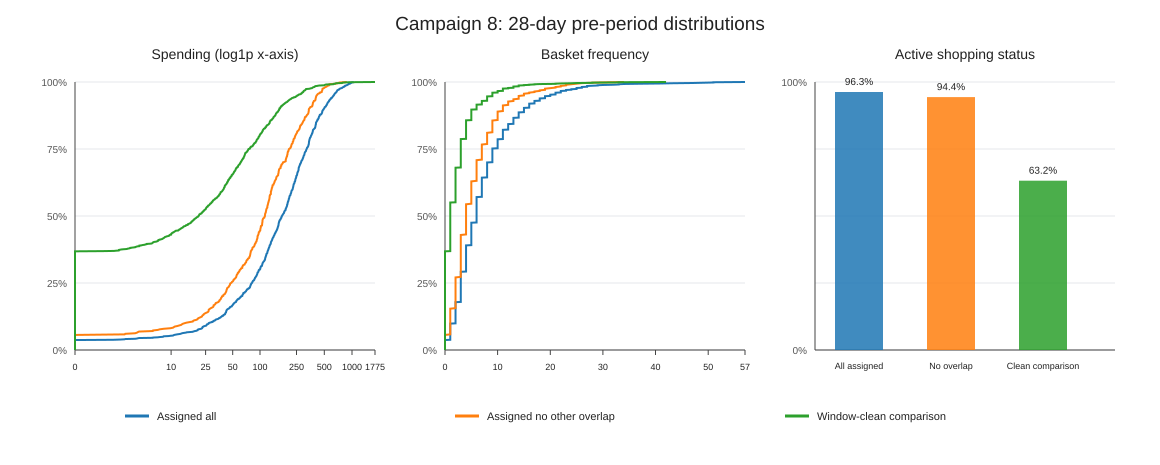

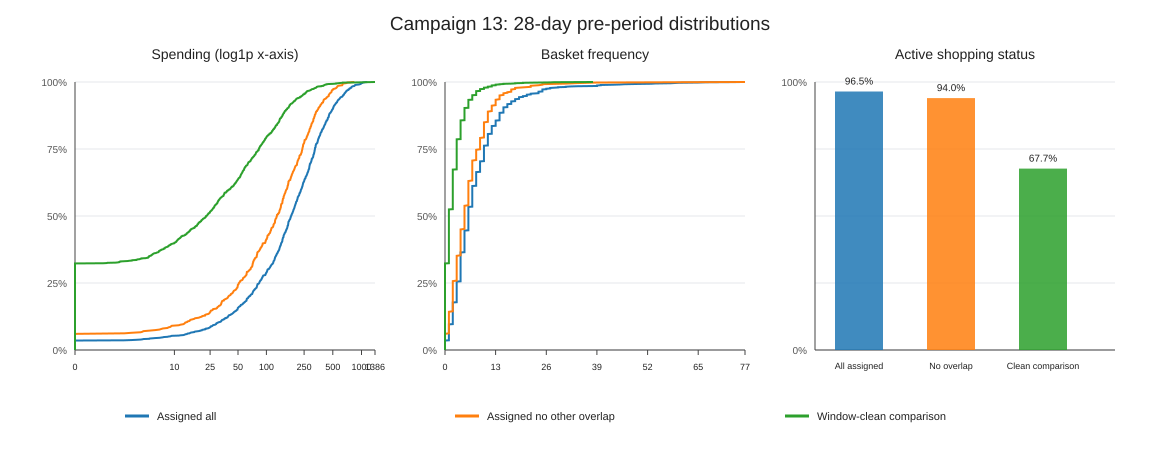

In [19]:
import html
import math
from IPython.display import SVG, display

plot_groups = (
    ("Assigned all", "assigned_all", "#1f77b4"),
    ("Assigned no other overlap", "assigned_no_overlap", "#ff7f0e"),
    ("Window-clean comparison", "window_clean_comparison", "#2ca02c"),
)

def svg_text(x, y, label, size=12, anchor="middle", color="#222"):
    return (
        f'<text x="{x:.1f}" y="{y:.1f}" font-size="{size}" '
        f'text-anchor="{anchor}" fill="{color}" font-family="Segoe UI,Arial,sans-serif">'
        f'{html.escape(str(label))}</text>'
    )

def ecdf_path(values, xmap, ymap):
    ordered = sorted(float(value) for value in values)
    if not ordered:
        return ""
    n = len(ordered)
    points = [f"M {xmap(ordered[0]):.2f} {ymap(0):.2f}"]
    points.extend(
        f"L {xmap(value):.2f} {ymap(index / n):.2f}"
        for index, value in enumerate(ordered, start=1)
    )
    return " ".join(points)

def campaign_svg(campaign_id):
    groups = []
    for label, cohort, color in plot_groups:
        frame = common_support_households.loc[
            (common_support_households.campaign_id == campaign_id)
            & (common_support_households.cohort == cohort)
        ]
        if len(frame):
            groups.append((label, color, frame))

    width, height = 1160, 465
    lefts, panel_w, top, bottom = (75, 445, 815), 300, 82, 350
    svg = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="white"/>',
        svg_text(width/2, 30, f"Campaign {campaign_id}: 28-day pre-period distributions", 19),
    ]
    for panel, title in enumerate(("Spending (log1p x-axis)", "Basket frequency", "Active shopping status")):
        left, right = lefts[panel], lefts[panel] + panel_w
        svg.append(svg_text(left + panel_w/2, 59, title, 14))
        for fraction in (0, .25, .5, .75, 1):
            y = bottom - fraction*(bottom-top)
            svg.append(f'<line x1="{left}" y1="{y:.1f}" x2="{right}" y2="{y:.1f}" stroke="#e5e7eb"/>')
            if panel < 2:
                svg.append(svg_text(left-8, y+4, f"{fraction:.0%}", 10, "end", "#555"))
        svg.append(f'<line x1="{left}" y1="{top}" x2="{left}" y2="{bottom}" stroke="#444"/>')
        svg.append(f'<line x1="{left}" y1="{bottom}" x2="{right}" y2="{bottom}" stroke="#444"/>')

        if panel == 0:
            maximum = max(float(v) for _, _, frame in groups for v in frame.pre_period_sales)
            xden = math.log1p(maximum) or 1
            xmap = lambda v: left + panel_w*math.log1p(max(0, v))/xden
            ticks = [0, 10, 25, 50, 100, 250, 500, 1000, 2500, 5000]
            ticks = [v for v in ticks if v <= maximum]
            if maximum and (not ticks or ticks[-1] != maximum):
                ticks.append(maximum)
            for tick in ticks:
                x = xmap(tick)
                svg.append(f'<line x1="{x:.1f}" y1="{bottom}" x2="{x:.1f}" y2="{bottom+5}" stroke="#444"/>')
                svg.append(svg_text(x, bottom+20, f"{tick:.0f}", 9))
            for _, color, frame in groups:
                svg.append(f'<path d="{ecdf_path(frame.pre_period_sales, xmap, lambda y: bottom-y*(bottom-top))}" fill="none" stroke="{color}" stroke-width="2"/>')
        elif panel == 1:
            maximum = max(int(v) for _, _, frame in groups for v in frame.pre_period_baskets)
            axis_max = max(1, maximum)
            xmap = lambda v: left + panel_w*max(0, v)/axis_max
            step = max(1, math.ceil(axis_max/6))
            ticks = list(range(0, axis_max+1, step))
            if ticks[-1] != axis_max:
                ticks.append(axis_max)
            for tick in ticks:
                x = xmap(tick)
                svg.append(f'<line x1="{x:.1f}" y1="{bottom}" x2="{x:.1f}" y2="{bottom+5}" stroke="#444"/>')
                svg.append(svg_text(x, bottom+20, tick, 9))
            for _, color, frame in groups:
                svg.append(f'<path d="{ecdf_path(frame.pre_period_baskets, xmap, lambda y: bottom-y*(bottom-top))}" fill="none" stroke="{color}" stroke-width="2"/>')
        else:
            for i, (label, color, frame) in enumerate(groups):
                active_pct = 100*float(frame.active_shopping.mean())
                x = left + 20 + i*92
                h = (bottom-top)*active_pct/100
                svg.append(f'<rect x="{x}" y="{bottom-h:.1f}" width="48" height="{h:.1f}" fill="{color}" opacity="0.85"/>')
                svg.append(svg_text(x+24, bottom-h-7, f"{active_pct:.1f}%", 10))
                short = ("All assigned", "No overlap", "Clean comparison")[i]
                svg.append(svg_text(x+24, bottom+19, short, 9))
            svg.append(svg_text(left-8, top+4, "100%", 10, "end", "#555"))
            svg.append(svg_text(left-8, bottom+4, "0%", 10, "end", "#555"))

    legend_y, cursor = 420, 125
    for label, color, frame in groups:
        svg.append(f'<line x1="{cursor}" y1="{legend_y-4}" x2="{cursor+24}" y2="{legend_y-4}" stroke="{color}" stroke-width="3"/>')
        svg.append(svg_text(cursor+32, legend_y, label, 11, "start"))
        cursor += 330
    svg.append("</svg>")
    return "".join(svg)

campaign8_svg = campaign_svg(8)
campaign13_svg = campaign_svg(13)
display(SVG(campaign8_svg))
display(SVG(campaign13_svg))


## Common-support interpretation and recommendation

The diagnostics use only the 28-day pre-period and campaign assignment/date information; no post-campaign outcomes were used to rank the candidates. The full evaluation windows are Campaign 8: pre 384–411, campaign 412–460, post 461–488; Campaign 13: pre 476–503, campaign 504–551, post 552–579. Each has 28 observed transaction days in both the pre and post windows, with no missing day indices.

Both assigned groups are much more active before treatment than their window-clean comparisons. Campaign 8 has 1,076 assigned households (480 with no other overlapping assignment) and 1,301 window-clean comparisons; Campaign 13 has 1,077 (498 clean-treated) and 1,319 comparisons. Pre-period active rates are 96.3% vs 63.2% for Campaign 8, and 96.5% vs 67.7% for Campaign 13. The percentile table above includes every cohort household, including zeros.

Against the comparison groups' marginal P10-P90 spending and basket ranges, the joint rectangular screen retains 423/1,076 (39.3%) of Campaign 8's assigned households and 350/1,077 (32.5%) of Campaign 13's. The stricter P25-P75 screen retains 179 (16.6%) and 188 (17.5%). Restricting treatment first to households with no other campaign assignment in the full evaluation window improves P10-P90 retention to 277/480 (57.7%) for Campaign 8 and 218/498 (43.8%) for Campaign 13, but those are only 25.7% and 20.2% of the original assigned populations. These range screens are descriptive diagnostics, not a matching procedure or a propensity-score estimate.

Demographics are substantially more incomplete among comparisons: a demographic row is available for 13.0% of Campaign 8 comparisons and 10.8% of Campaign 13 comparisons, versus 53.8% and 56.6% of all assigned households. Missingness across each listed demographic field is 87.0%/89.2% for comparisons, versus 46.2%/43.4% for assigned households. Among nonmissing records, categorical balance is mixed and the comparison samples are small; these observed characteristics cannot address unmeasured selection bias.

**Recommendation:** Neither candidate has adequate common support for matching the full assigned population without excluding most treated households. Campaign 8 is the less weak candidate for a narrowly defined, overlap-free subgroup, but support and demographic missingness remain limiting. Reconsider the other 25 date-eligible campaigns before selecting a matching target. Do not match or estimate effects yet.


## Campaign screening: all date-eligible campaigns

This screen includes campaigns with at least 28 observed transaction days before and after the campaign (start day >= 29 and end day <= 683, using the verified transaction-day range 1–711). Assignment is a treatment-assignment proxy, not confirmed exposure.

For each campaign, the clean treated cohort excludes households assigned to another campaign whose dates intersect the candidate's complete pre/during/post window. Window-clean comparisons are not assigned to the candidate or to any campaign overlapping that window. Every household remains in the baseline summaries; zero-spend households are retained.

The broad P10–P90 result is a rectangular range check. The separate two-dimensional support check uses standardized log1p(pre-period sales) and log1p(pre-period baskets): a treated household is locally supported when its fifth-nearest clean comparison is no farther than the comparison group's 95th-percentile leave-one-out fifth-nearest-neighbor distance. This checks joint local density rather than separate marginal ranges. It is a diagnostic threshold, not matching.

Ranking rules are fixed before looking at the results. The 10-point score gives 0–2 points for clean treated N (<100, 100–199, >=200); 0–2 for the maximum absolute clean-treated SMD across sales, baskets and active status (>0.20, 0.10–0.20, <=0.10); 0–2 for joint 2D support (<50%, 50–69.9%, >=70%); 0–2 for the fraction of original assignments retained without overlapping assignment (<50%, 50–69.9%, >=70%); 1 point for complete 28-day pre/post transaction coverage; and 1 point when there are at least 100 clean comparisons and at least one per clean treated household. The clean-cohort comparison count is only a minimum availability gate; it does not itself establish common support. Ties are ordered by higher 2D support, lower clean-cohort maximum |SMD|, then larger clean treated N. These are screening tiers, not a power calculation.

No campaign-period or post-period sales are used in the metrics or ranking.


In [20]:
import numpy as np
import pandas as pd
from sqlalchemy import text

all_campaign_screen_query = text("""
    WITH eligible_campaigns AS (
        SELECT campaign_id, campaign_type, start_day, end_day,
               end_day - start_day + 1 AS duration_days,
               start_day - 28 AS pre_start_day,
               start_day - 1 AS pre_end_day,
               end_day + 1 AS post_start_day,
               end_day + 28 AS post_end_day
        FROM dbt_dev.dim_campaign
        WHERE start_day >= 29 AND end_day <= 683
    ),
    households AS (
        SELECT DISTINCT household_key FROM dbt_dev.dim_household
    ),
    assignment_pairs AS (
        SELECT DISTINCT household_key, campaign_id
        FROM dbt_dev.bridge_household_campaign
    ),
    overlapping_campaigns AS (
        SELECT c.campaign_id AS candidate_id,
               other.campaign_id AS other_campaign_id
        FROM eligible_campaigns AS c
        JOIN dbt_dev.dim_campaign AS other
          ON other.campaign_id <> c.campaign_id
         AND other.start_day <= c.post_end_day
         AND other.end_day >= c.pre_start_day
    ),
    pre_sales AS (
        SELECT c.campaign_id, s.household_key,
               SUM(s.sales_value)::numeric AS pre_period_sales
        FROM eligible_campaigns AS c
        JOIN dbt_dev.fct_sales AS s
          ON s.transaction_day BETWEEN c.pre_start_day AND c.pre_end_day
        GROUP BY c.campaign_id, s.household_key
    ),
    pre_baskets AS (
        SELECT c.campaign_id, b.household_key,
               COUNT(DISTINCT b.basket_id)::integer AS pre_period_baskets
        FROM eligible_campaigns AS c
        JOIN dbt_dev.fct_baskets AS b
          ON b.transaction_day BETWEEN c.pre_start_day AND c.pre_end_day
        GROUP BY c.campaign_id, b.household_key
    ),
    pre_household AS (
        SELECT COALESCE(s.campaign_id, b.campaign_id) AS campaign_id,
               COALESCE(s.household_key, b.household_key) AS household_key,
               s.pre_period_sales, b.pre_period_baskets
        FROM pre_sales AS s
        FULL OUTER JOIN pre_baskets AS b
          ON b.campaign_id = s.campaign_id
         AND b.household_key = s.household_key
    )
    SELECT c.campaign_id, c.campaign_type, c.start_day, c.end_day,
           c.duration_days, h.household_key,
           (a.household_key IS NOT NULL) AS assigned_candidate,
           EXISTS (
               SELECT 1
               FROM assignment_pairs AS oa
               JOIN overlapping_campaigns AS o
                 ON o.candidate_id = c.campaign_id
                AND o.other_campaign_id = oa.campaign_id
               WHERE oa.household_key = h.household_key
           ) AS has_other_overlapping_assignment,
           COALESCE(p.pre_period_sales, 0)::numeric AS pre_period_sales,
           COALESCE(p.pre_period_baskets, 0)::integer AS pre_period_baskets,
           (p.household_key IS NOT NULL) AS active_pre_period
    FROM eligible_campaigns AS c
    CROSS JOIN households AS h
    LEFT JOIN assignment_pairs AS a
      ON a.campaign_id = c.campaign_id
     AND a.household_key = h.household_key
    LEFT JOIN pre_household AS p
      ON p.campaign_id = c.campaign_id
     AND p.household_key = h.household_key
    ORDER BY c.campaign_id, h.household_key
""")

with engine.connect() as conn:
    all_campaign_households = pd.read_sql_query(all_campaign_screen_query, conn)
    observed_transaction_days = pd.read_sql_query(text("""
        SELECT DISTINCT transaction_day
        FROM dbt_dev.fct_sales
        WHERE transaction_day IS NOT NULL
    """), conn)["transaction_day"].astype(int).tolist()
    all_campaign_calendar = pd.read_sql_query(text("""
        SELECT campaign_id, start_day, end_day
        FROM dbt_dev.dim_campaign
    """), conn)

for column in ("pre_period_sales", "pre_period_baskets"):
    all_campaign_households[column] = pd.to_numeric(
        all_campaign_households[column], errors="coerce"
    ).fillna(0)
all_campaign_households["pre_period_baskets"] = (
    all_campaign_households["pre_period_baskets"].astype(int)
)
all_campaign_households["active_pre_period"] = (
    all_campaign_households["active_pre_period"].fillna(False).astype(bool)
)
all_campaign_households["assigned_candidate"] = (
    all_campaign_households["assigned_candidate"].fillna(False).astype(bool)
)
all_campaign_households["has_other_overlapping_assignment"] = (
    all_campaign_households["has_other_overlapping_assignment"].fillna(False).astype(bool)
)

eligible_campaigns_screened = (
    all_campaign_households[
        ["campaign_id", "campaign_type", "start_day", "end_day", "duration_days"]
    ].drop_duplicates().sort_values("campaign_id").reset_index(drop=True)
)
transaction_day_set = set(observed_transaction_days)
coverage_rows = []
# Overlap dates include every campaign, including campaigns that fail date eligibility.
all_campaign_dates = all_campaign_calendar.to_dict("records")
for campaign in all_campaign_dates:
    campaign_id = int(campaign["campaign_id"])
    start_day, end_day = int(campaign["start_day"]), int(campaign["end_day"])
    overlaps = [
        other for other in all_campaign_dates
        if int(other["campaign_id"]) != campaign_id
        and int(other["start_day"]) <= end_day + 28
        and int(other["end_day"]) >= start_day - 28
    ]
    pre_expected = list(range(start_day - 28, start_day))
    during_expected = list(range(start_day, end_day + 1))
    post_expected = list(range(end_day + 1, end_day + 29))
    pre_observed = sum(day in transaction_day_set for day in pre_expected)
    during_observed = sum(day in transaction_day_set for day in during_expected)
    post_observed = sum(day in transaction_day_set for day in post_expected)
    coverage_rows.append({
        "campaign_id": campaign_id,
        "date_overlapping_campaign_count": len(overlaps),
        "date_overlapping_campaign_ids": ", ".join(
            str(int(other["campaign_id"])) for other in sorted(overlaps, key=lambda x: x["campaign_id"])
        ) or "none",
        "pre_days_observed": pre_observed,
        "pre_days_expected": 28,
        "campaign_days_observed": during_observed,
        "campaign_days_expected": len(during_expected),
        "post_days_observed": post_observed,
        "post_days_expected": 28,
        "coverage_complete": pre_observed == 28 and during_observed == len(during_expected) and post_observed == 28,
    })
campaign_window_coverage = pd.DataFrame(coverage_rows)
print("Date-eligible campaigns screened:", eligible_campaigns_screened.campaign_id.nunique())
print("Household-campaign rows:", len(all_campaign_households))
print("Observed transaction day indices:", len(transaction_day_set))


Date-eligible campaigns screened: 25
Household-campaign rows: 62500
Observed transaction day indices: 711


In [21]:
import math

quantile_levels = (0.10, 0.25, 0.50, 0.75, 0.90)
distribution_rows = []
screen_rows = []

def sample_smd(treated_values, comparison_values):
    t = pd.Series(treated_values, dtype="float64")
    c = pd.Series(comparison_values, dtype="float64")
    pooled = math.sqrt((float(t.std(ddof=1) or 0.0) ** 2 + float(c.std(ddof=1) or 0.0) ** 2) / 2)
    return float((t.mean() - c.mean()) / pooled) if pooled else 0.0

def nearest_fifth_support(treated_frame, control_frame, k=5):
    if len(treated_frame) == 0 or len(control_frame) <= k:
        return {"supported_n": 0, "supported_pct": 0.0, "cutoff": None, "p50_distance": None, "p90_distance": None}
    # log1p reduces skew; scale by clean-control SD so neither dimension dominates by units.
    controls = np.column_stack((
        np.log1p(control_frame.pre_period_sales.to_numpy(dtype=float)),
        np.log1p(control_frame.pre_period_baskets.to_numpy(dtype=float)),
    ))
    treated = np.column_stack((
        np.log1p(treated_frame.pre_period_sales.to_numpy(dtype=float)),
        np.log1p(treated_frame.pre_period_baskets.to_numpy(dtype=float)),
    ))
    center = controls.mean(axis=0)
    scale = controls.std(axis=0, ddof=1)
    scale[~np.isfinite(scale) | (scale == 0)] = 1.0
    controls = (controls - center) / scale
    treated = (treated - center) / scale
    control_norm = np.einsum("ij,ij->i", controls, controls)
    control_d2 = control_norm[:, None] + control_norm[None, :] - 2 * controls @ controls.T
    np.maximum(control_d2, 0, out=control_d2)
    np.fill_diagonal(control_d2, np.inf)
    control_5nn = np.sqrt(np.partition(control_d2, k - 1, axis=1)[:, k - 1])
    treated_norm = np.einsum("ij,ij->i", treated, treated)
    treated_d2 = treated_norm[:, None] + control_norm[None, :] - 2 * treated @ controls.T
    np.maximum(treated_d2, 0, out=treated_d2)
    treated_5nn = np.sqrt(np.partition(treated_d2, k - 1, axis=1)[:, k - 1])
    cutoff = float(np.quantile(control_5nn, 0.95))
    supported = treated_5nn <= cutoff
    return {
        "supported_n": int(supported.sum()),
        "supported_pct": round(100 * float(supported.mean()), 1),
        "cutoff": round(cutoff, 4),
        "p50_distance": round(float(np.quantile(treated_5nn, 0.50)), 4),
        "p90_distance": round(float(np.quantile(treated_5nn, 0.90)), 4),
    }

for campaign_id in eligible_campaigns_screened.campaign_id.astype(int):
    group = all_campaign_households.loc[
        all_campaign_households.campaign_id == campaign_id
    ].copy()
    assigned = group.loc[group.assigned_candidate]
    clean_treated = assigned.loc[~assigned.has_other_overlapping_assignment]
    potential_comparison = group.loc[~group.assigned_candidate]
    clean_comparison = potential_comparison.loc[
        ~potential_comparison.has_other_overlapping_assignment
    ]
    campaign_info = eligible_campaigns_screened.loc[
        eligible_campaigns_screened.campaign_id == campaign_id
    ].iloc[0]
    coverage = campaign_window_coverage.loc[
        campaign_window_coverage.campaign_id == campaign_id
    ].iloc[0]

    cohort_groups = (
        ("assigned_all", assigned),
        ("assigned_no_overlap", clean_treated),
        ("window_clean_comparison", clean_comparison),
    )
    for cohort_name, cohort in cohort_groups:
        sales_q = cohort.pre_period_sales.quantile(quantile_levels)
        basket_q = cohort.pre_period_baskets.quantile(quantile_levels)
        distribution_rows.append({
            "campaign_id": int(campaign_id),
            "campaign_type": campaign_info.campaign_type,
            "cohort": cohort_name,
            "households": len(cohort),
            "sales_zero_n_pct": f"{int((cohort.pre_period_sales == 0).sum())} ({100 * float((cohort.pre_period_sales == 0).mean()):.1f}%)",
            "basket_zero_n_pct": f"{int((cohort.pre_period_baskets == 0).sum())} ({100 * float((cohort.pre_period_baskets == 0).mean()):.1f}%)",
            "active_pct": round(100 * float(cohort.active_pre_period.mean()), 1) if len(cohort) else None,
            **{f"sales_p{int(level*100)}": round(float(sales_q.loc[level]), 2) for level in quantile_levels},
            **{f"baskets_p{int(level*100)}": round(float(basket_q.loc[level]), 2) for level in quantile_levels},
        })

    clean_sales_q = clean_comparison.pre_period_sales.quantile([0.10, 0.90])
    clean_basket_q = clean_comparison.pre_period_baskets.quantile([0.10, 0.90])
    def p1090_range_support(treated):
        in_sales = treated.pre_period_sales.between(clean_sales_q.loc[0.10], clean_sales_q.loc[0.90])
        in_baskets = treated.pre_period_baskets.between(clean_basket_q.loc[0.10], clean_basket_q.loc[0.90])
        supported = in_sales & in_baskets
        return int(supported.sum()), round(100 * float(supported.mean()), 1) if len(treated) else 0.0

    rect_all_n, rect_all_pct = p1090_range_support(assigned)
    rect_clean_n, rect_clean_pct = p1090_range_support(clean_treated)
    knn_all = nearest_fifth_support(assigned, clean_comparison)
    knn_clean = nearest_fifth_support(clean_treated, clean_comparison)
    coverage_ok = bool(coverage.coverage_complete)
    coassigned_n = len(assigned) - len(clean_treated)
    comparison_ratio = len(clean_comparison) / len(clean_treated) if len(clean_treated) else 0.0
    s_all = {
        "sales": sample_smd(assigned.pre_period_sales, clean_comparison.pre_period_sales),
        "baskets": sample_smd(assigned.pre_period_baskets, clean_comparison.pre_period_baskets),
        "active": sample_smd(assigned.active_pre_period.astype(int), clean_comparison.active_pre_period.astype(int)),
    }
    s_clean = {
        "sales": sample_smd(clean_treated.pre_period_sales, clean_comparison.pre_period_sales),
        "baskets": sample_smd(clean_treated.pre_period_baskets, clean_comparison.pre_period_baskets),
        "active": sample_smd(clean_treated.active_pre_period.astype(int), clean_comparison.active_pre_period.astype(int)),
    }
    screen_rows.append({
        "campaign_id": int(campaign_id),
        "campaign_type": campaign_info.campaign_type,
        "campaign_days": f"{int(campaign_info.start_day)}-{int(campaign_info.end_day)}",
        "duration_days": int(campaign_info.duration_days),
        "assigned_n": len(assigned),
        "no_overlap_treated_n": len(clean_treated),
        "retained_after_overlap_pct": round(100 * len(clean_treated) / len(assigned), 1) if len(assigned) else 0.0,
        "coassigned_n": coassigned_n,
        "coassigned_pct": round(100 * coassigned_n / len(assigned), 1) if len(assigned) else 0.0,
        "potential_comparison_n": len(potential_comparison),
        "window_clean_comparison_n": len(clean_comparison),
        "clean_comparisons_per_clean_treated": round(comparison_ratio, 2),
        "active_pct_assigned": round(100 * float(assigned.active_pre_period.mean()), 1) if len(assigned) else None,
        "active_pct_no_overlap": round(100 * float(clean_treated.active_pre_period.mean()), 1) if len(clean_treated) else None,
        "active_pct_comparison": round(100 * float(clean_comparison.active_pre_period.mean()), 1) if len(clean_comparison) else None,
        "sales_smd_all": round(s_all["sales"], 3),
        "baskets_smd_all": round(s_all["baskets"], 3),
        "active_smd_all": round(s_all["active"], 3),
        "sales_smd_clean": round(s_clean["sales"], 3),
        "baskets_smd_clean": round(s_clean["baskets"], 3),
        "active_smd_clean": round(s_clean["active"], 3),
        "max_abs_smd_clean": round(max(abs(x) for x in s_clean.values()), 3),
        "p10p90_joint_all_n": rect_all_n,
        "p10p90_joint_all_pct": rect_all_pct,
        "p10p90_joint_clean_n": rect_clean_n,
        "p10p90_joint_clean_pct": rect_clean_pct,
        "p10p90_clean_retained_pct_original": round(100 * rect_clean_n / len(assigned), 1) if len(assigned) else 0.0,
        "joint_5nn_all_n": knn_all["supported_n"],
        "joint_5nn_all_pct": knn_all["supported_pct"],
        "joint_5nn_clean_n": knn_clean["supported_n"],
        "joint_5nn_clean_pct": knn_clean["supported_pct"],
        "joint_5nn_clean_retained_pct_original": round(100 * knn_clean["supported_n"] / len(assigned), 1) if len(assigned) else 0.0,
        "joint_5nn_control_p95_cutoff": knn_clean["cutoff"],
        "joint_5nn_clean_treated_p90_distance": knn_clean["p90_distance"],
        "date_overlapping_campaign_count": int(coverage.date_overlapping_campaign_count),
        "date_overlapping_campaign_ids": coverage.date_overlapping_campaign_ids,
        "pre_days_observed": int(coverage.pre_days_observed),
        "post_days_observed": int(coverage.post_days_observed),
        "coverage_complete": coverage_ok,
    })

screening_distributions_25 = pd.DataFrame(distribution_rows)
screening_summary_25 = pd.DataFrame(screen_rows)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
print("Screening summary rows:", len(screening_summary_25))
print("Campaigns with complete pre/during/post day coverage:", int(screening_summary_25.coverage_complete.sum()))
display(screening_distributions_25)


Screening summary rows: 25
Campaigns with complete pre/during/post day coverage: 25


,campaign_id,campaign_type,cohort,households,sales_zero_n_pct,basket_zero_n_pct,active_pct,sales_p10,sales_p25,sales_p50,sales_p75,sales_p90,baskets_p10,baskets_p25,baskets_p50,baskets_p75,baskets_p90
0,1,TypeB,assigned_all,13,0 (0.0%),0 (0.0%),100.0,64.07,72.43,188.91,251.98,324.09,1.0,3.00,5.0,8.00,13.6
1,1,TypeB,assigned_no_overlap,2,0 (0.0%),0 (0.0%),100.0,45.13,48.16,53.21,58.26,61.29,1.3,1.75,2.5,3.25,3.7
2,1,TypeB,window_clean_comparison,1774,507 (28.6%),507 (28.6%),71.4,0.00,0.00,42.52,136.07,262.20,0.0,0.00,2.0,4.00,8.0
3,2,TypeB,assigned_all,48,1 (2.1%),1 (2.1%),97.9,44.09,85.34,152.87,256.06,341.80,2.0,3.00,6.0,8.00,12.0
4,2,TypeB,assigned_no_overlap,12,0 (0.0%),0 (0.0%),100.0,39.11,54.24,98.46,214.17,293.12,2.0,2.75,4.5,8.00,9.8
5,2,TypeB,window_clean_comparison,1774,500 (28.2%),500 (28.2%),71.8,0.00,0.00,41.47,129.70,251.31,0.0,0.00,2.0,4.00,8.0
6,3,TypeC,assigned_all,12,0 (0.0%),0 (0.0%),100.0,68.63,174.75,292.00,399.41,674.63,3.1,5.50,8.0,13.50,20.7
7,3,TypeC,assigned_no_overlap,0,0 (nan%),0 (nan%),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,3,TypeC,window_clean_comparison,1240,482 (38.9%),482 (38.9%),61.1,0.00,0.00,15.40,72.17,164.75,0.0,0.00,1.0,3.00,5.0
9,4,TypeB,assigned_all,81,2 (2.5%),2 (2.5%),97.5,52.88,130.36,216.34,378.10,551.91,2.0,5.00,7.0,11.00,15.0


In [22]:
# Predefined ordinal scoring tiers; these are feasibility flags, not effect estimates.
pd.set_option("display.max_columns", None)
ranked_campaign_screen = screening_summary_25.copy()

def sample_score(n):
    return 2 if n >= 200 else (1 if n >= 100 else 0)

def smd_score(value):
    return 2 if value <= 0.10 else (1 if value <= 0.20 else 0)

def proportion_score(value):
    return 2 if value >= 70 else (1 if value >= 50 else 0)

ranked_campaign_screen["score_clean_sample"] = ranked_campaign_screen.no_overlap_treated_n.map(sample_score)
ranked_campaign_screen["treatment_sample_flag"] = ranked_campaign_screen.no_overlap_treated_n.map(
    lambda n: "very small (<100)" if n < 100 else ("limited (100-199)" if n < 200 else "usable (>=200)")
)
ranked_campaign_screen["score_clean_baseline_balance"] = ranked_campaign_screen.max_abs_smd_clean.map(smd_score)
ranked_campaign_screen["score_joint_2d_support"] = ranked_campaign_screen.joint_5nn_clean_pct.map(proportion_score)
ranked_campaign_screen["score_assignment_retention"] = ranked_campaign_screen.retained_after_overlap_pct.map(proportion_score)
ranked_campaign_screen["score_comparison_availability"] = (
    (ranked_campaign_screen.window_clean_comparison_n >= 100)
    & (ranked_campaign_screen.window_clean_comparison_n >= ranked_campaign_screen.no_overlap_treated_n)
).astype(int)
ranked_campaign_screen["score_coverage"] = ranked_campaign_screen.coverage_complete.astype(int)
ranked_campaign_screen["joint_support_flag"] = ranked_campaign_screen.joint_5nn_clean_pct.map(
    lambda x: "poor (<50%)" if x < 50 else ("moderate (50-69.9%)" if x < 70 else "strong (>=70%)")
)
ranked_campaign_screen["comparison_availability_flag"] = ranked_campaign_screen.apply(
    lambda row: "adequate count gate" if row.window_clean_comparison_n >= max(100, row.no_overlap_treated_n)
    else "limited count gate",
    axis=1,
)
score_columns = [
    "score_clean_sample", "score_clean_baseline_balance", "score_joint_2d_support",
    "score_assignment_retention", "score_comparison_availability", "score_coverage",
]
ranked_campaign_screen["feasibility_score_10"] = ranked_campaign_screen[score_columns].sum(axis=1)
ranked_campaign_screen["credible_screen_pass"] = (
    (ranked_campaign_screen.no_overlap_treated_n >= 100)
    & (ranked_campaign_screen.max_abs_smd_clean <= 0.20)
    & (ranked_campaign_screen.joint_5nn_clean_pct >= 50)
    & (ranked_campaign_screen.retained_after_overlap_pct >= 50)
    & (ranked_campaign_screen.window_clean_comparison_n >= 100)
    & (ranked_campaign_screen.window_clean_comparison_n >= ranked_campaign_screen.no_overlap_treated_n)
    & ranked_campaign_screen.coverage_complete
)
ranked_campaign_screen = ranked_campaign_screen.sort_values(
    ["feasibility_score_10", "joint_5nn_clean_pct", "max_abs_smd_clean", "no_overlap_treated_n"],
    ascending=[False, False, True, False],
).reset_index(drop=True)
ranked_campaign_screen.insert(0, "rank", np.arange(1, len(ranked_campaign_screen) + 1))

ranking_columns = [
    "rank", "campaign_id", "campaign_type", "campaign_days", "assigned_n",
    "no_overlap_treated_n", "treatment_sample_flag", "retained_after_overlap_pct", "potential_comparison_n",
    "window_clean_comparison_n", "comparison_availability_flag", "coassigned_pct", "active_pct_no_overlap",
    "active_pct_assigned", "active_pct_comparison", "sales_smd_all", "baskets_smd_all", "active_smd_all",
    "sales_smd_clean", "baskets_smd_clean", "active_smd_clean", "max_abs_smd_clean",
    "p10p90_joint_all_pct", "p10p90_joint_clean_pct", "p10p90_clean_retained_pct_original",
    "joint_5nn_all_pct", "joint_5nn_clean_pct", "joint_support_flag",
    "joint_5nn_clean_retained_pct_original", "date_overlapping_campaign_count", "date_overlapping_campaign_ids",
    "pre_days_observed", "post_days_observed", "feasibility_score_10", "credible_screen_pass",
]
ranked_campaign_screen_display = ranked_campaign_screen[ranking_columns]
top3_campaign_screen = ranked_campaign_screen_display.head(3).copy()
print("Predefined scoring tiers and credible-screen gate applied to all campaigns.")
print("Campaigns passing the complete minimum credible-screen gate:", int(ranked_campaign_screen.credible_screen_pass.sum()))
display(ranked_campaign_screen_display)
display(top3_campaign_screen)


Predefined scoring tiers and credible-screen gate applied to all campaigns.
Campaigns passing the complete minimum credible-screen gate: 0


,rank,campaign_id,campaign_type,campaign_days,assigned_n,no_overlap_treated_n,treatment_sample_flag,retained_after_overlap_pct,potential_comparison_n,window_clean_comparison_n,comparison_availability_flag,coassigned_pct,active_pct_no_overlap,active_pct_assigned,active_pct_comparison,sales_smd_all,baskets_smd_all,active_smd_all,sales_smd_clean,baskets_smd_clean,active_smd_clean,max_abs_smd_clean,p10p90_joint_all_pct,p10p90_joint_clean_pct,p10p90_clean_retained_pct_original,joint_5nn_all_pct,joint_5nn_clean_pct,joint_support_flag,joint_5nn_clean_retained_pct_original,date_overlapping_campaign_count,date_overlapping_campaign_ids,pre_days_observed,post_days_observed,feasibility_score_10,credible_screen_pass
0,1,26,TypeA,224-264,332,282,usable (>=200),84.9,2168,2078,adequate count gate,15.1,94.0,94.3,75.6,0.544,0.479,0.542,0.488,0.452,0.530,0.530,64.2,66.7,56.6,89.8,88.7,strong (>=70%),75.3,3,"27, 28, 29",28,28,8,False
1,2,30,TypeA,323-369,361,212,usable (>=200),58.7,2139,1855,adequate count gate,41.3,91.0,93.1,72.1,0.682,0.546,0.575,0.458,0.434,0.503,0.503,61.8,68.9,40.4,85.9,87.7,strong (>=70%),51.5,9,"1, 2, 3, 4, 5, 6, 27, 28, 29",28,28,7,False
2,3,8,TypeA,412-460,1076,480,usable (>=200),44.6,1424,1301,adequate count gate,55.4,94.4,96.3,63.2,1.028,0.946,0.903,0.702,0.728,0.825,0.825,39.3,57.7,25.7,76.4,86.9,strong (>=70%),38.8,9,"3, 4, 5, 6, 7, 9, 10, 11, 12",28,28,6,False
3,4,18,TypeA,587-642,1133,455,usable (>=200),40.2,1367,1231,adequate count gate,59.8,92.1,96.2,65.5,1.054,0.978,0.848,0.619,0.746,0.688,0.746,32.7,50.1,20.1,71.9,81.1,strong (>=70%),32.6,11,"14, 15, 16, 17, 19, 20, 21, 22, 23, 24, 25",28,28,6,False
4,5,13,TypeA,504-551,1077,498,usable (>=200),46.2,1423,1319,adequate count gate,53.8,94.0,96.5,67.7,1.096,0.959,0.809,0.826,0.837,0.708,0.837,32.5,43.8,20.2,66.2,76.5,strong (>=70%),35.4,7,"10, 11, 12, 14, 15, 16, 17",28,28,6,False
5,6,10,TypeB,463-495,123,3,very small (<100),2.4,2377,1177,adequate count gate,97.6,66.7,96.7,63.0,1.438,1.226,0.926,-0.194,-0.027,0.068,0.194,22.0,100.0,2.4,54.5,100.0,strong (>=70%),2.4,5,"8, 9, 11, 12, 13",28,28,5,False
6,7,29,TypeB,281-334,118,77,very small (<100),65.3,2382,1953,adequate count gate,34.7,96.1,95.8,75.2,0.514,0.412,0.610,0.464,0.380,0.625,0.625,72.0,74.0,48.3,94.9,92.2,strong (>=70%),60.2,7,"1, 2, 3, 26, 27, 28, 30",28,28,5,False
7,8,1,TypeB,346-383,13,2,very small (<100),15.4,2487,1774,adequate count gate,84.6,100.0,100.0,71.4,0.731,0.561,0.894,-0.415,-0.225,0.894,0.894,69.2,100.0,15.4,84.6,100.0,strong (>=70%),15.4,9,"2, 3, 4, 5, 6, 7, 28, 29, 30",28,28,4,False
8,9,6,TypeC,393-425,65,1,very small (<100),1.5,2435,1256,adequate count gate,98.5,100.0,98.5,62.9,1.835,1.300,1.008,NaN,NaN,NaN,NaN,9.2,0.0,0.0,56.9,100.0,strong (>=70%),1.5,9,"1, 2, 3, 4, 5, 7, 8, 9, 30",28,28,4,False
9,10,22,TypeB,624-656,276,13,very small (<100),4.7,2224,1241,adequate count gate,95.3,100.0,99.6,67.7,1.517,1.238,0.958,0.685,0.361,0.977,0.977,18.1,61.5,2.9,54.3,92.3,strong (>=70%),4.3,10,"14, 15, 17, 18, 19, 20, 21, 23, 24, 25",28,28,4,False


,rank,campaign_id,campaign_type,campaign_days,assigned_n,no_overlap_treated_n,treatment_sample_flag,retained_after_overlap_pct,potential_comparison_n,window_clean_comparison_n,comparison_availability_flag,coassigned_pct,active_pct_no_overlap,active_pct_assigned,active_pct_comparison,sales_smd_all,baskets_smd_all,active_smd_all,sales_smd_clean,baskets_smd_clean,active_smd_clean,max_abs_smd_clean,p10p90_joint_all_pct,p10p90_joint_clean_pct,p10p90_clean_retained_pct_original,joint_5nn_all_pct,joint_5nn_clean_pct,joint_support_flag,joint_5nn_clean_retained_pct_original,date_overlapping_campaign_count,date_overlapping_campaign_ids,pre_days_observed,post_days_observed,feasibility_score_10,credible_screen_pass
0,1,26,TypeA,224-264,332,282,usable (>=200),84.9,2168,2078,adequate count gate,15.1,94.0,94.3,75.6,0.544,0.479,0.542,0.488,0.452,0.530,0.530,64.2,66.7,56.6,89.8,88.7,strong (>=70%),75.3,3,"27, 28, 29",28,28,8,False
1,2,30,TypeA,323-369,361,212,usable (>=200),58.7,2139,1855,adequate count gate,41.3,91.0,93.1,72.1,0.682,0.546,0.575,0.458,0.434,0.503,0.503,61.8,68.9,40.4,85.9,87.7,strong (>=70%),51.5,9,"1, 2, 3, 4, 5, 6, 27, 28, 29",28,28,7,False
2,3,8,TypeA,412-460,1076,480,usable (>=200),44.6,1424,1301,adequate count gate,55.4,94.4,96.3,63.2,1.028,0.946,0.903,0.702,0.728,0.825,0.825,39.3,57.7,25.7,76.4,86.9,strong (>=70%),38.8,9,"3, 4, 5, 6, 7, 9, 10, 11, 12",28,28,6,False


In [23]:
from IPython.display import Markdown, display

top_lines = []
for _, row in top3_campaign_screen.iterrows():
    top_lines.append(
        f"- **{int(row.campaign_id)} ({row.campaign_type}):** score {int(row.feasibility_score_10)}/10; "
        f"{int(row.no_overlap_treated_n)}/{int(row.assigned_n)} assigned households remain after overlap exclusion "
        f"({row.retained_after_overlap_pct:.1f}%); clean-cohort max |SMD| {row.max_abs_smd_clean:.3f}; "
        f"joint 2D local support {row.joint_5nn_clean_pct:.1f}% of the no-overlap treated group."
    )
if int(ranked_campaign_screen.credible_screen_pass.sum()) == 0:
    decision = (
        "No campaign passes the predeclared minimum feasibility gate. The relative top three are screening leads, "
        "not credible causal candidates. Reconsider the date-eligible set rather than forcing matching."
    )
else:
    passed_ids = ", ".join(str(int(x)) for x in ranked_campaign_screen.loc[ranked_campaign_screen.credible_screen_pass, "campaign_id"])
    decision = f"Campaigns {passed_ids} pass the minimum feasibility gate for further design review; this is not approval to match or estimate effects."
display(Markdown(
    "## Campaign screening findings\n\n"
    + "\n".join(top_lines)
    + "\n\n**Screen decision:** " + decision
    + "\n\nAssignment records indicate assignment, not confirmed exposure. A restricted-cohort result would target only households assigned to the campaign, unassigned to other overlapping campaigns, and within the prespecified support region. It would not represent all assigned households. Demographic missingness and unmeasured targeting remain concerns. No matching or treatment-effect estimation was performed."
))


## Campaign screening findings

- **26 (TypeA):** score 8/10; 282/332 assigned households remain after overlap exclusion (84.9%); clean-cohort max |SMD| 0.530; joint 2D local support 88.7% of the no-overlap treated group.
- **30 (TypeA):** score 7/10; 212/361 assigned households remain after overlap exclusion (58.7%); clean-cohort max |SMD| 0.503; joint 2D local support 87.7% of the no-overlap treated group.
- **8 (TypeA):** score 6/10; 480/1076 assigned households remain after overlap exclusion (44.6%); clean-cohort max |SMD| 0.825; joint 2D local support 86.9% of the no-overlap treated group.

**Screen decision:** No campaign passes the predeclared minimum feasibility gate. The relative top three are screening leads, not credible causal candidates. Reconsider the date-eligible set rather than forcing matching.

Assignment records indicate assignment, not confirmed exposure. A restricted-cohort result would target only households assigned to the campaign, unassigned to other overlapping campaigns, and within the prespecified support region. It would not represent all assigned households. Demographic missingness and unmeasured targeting remain concerns. No matching or treatment-effect estimation was performed.

## Matching feasibility (Campaign 26, design only)

Treatment is assignment to Campaign 26 with no assignment to another campaign whose dates overlap the complete evaluation window, days 196–292. The initial control pool is the 2,078 window-clean comparison households. Assignment is not confirmed exposure.

All matching features use only transaction history before Campaign 26 starts on day 224: three 28-day periods (days 140–167, 168–195 and 196–223), 12 weekly sales totals, 84-day purchase recency, and earlier campaign-assignment count. Zero-spend households remain. Recent 28-day activity is exactly matched. A feature constant across the treatment/control pool is excluded from distance. Demographics are assessed for missingness and balance but are not used as a complete-case filter. The database has no assignment timestamp, so pre-campaign-start is the earliest verifiable timing; these features cannot be confirmed as preceding assignment notification.

The trial is deterministic 1:1 greedy nearest-neighbour matching without replacement. Euclidean distance uses predeclared log1p sales/basket measures, previous activity, recency, the 12-week log-sales slope and prior assignment count, scaled by clean-control standard deviations. Treatment and control must have the same recent activity status. The distance limit is the clean controls’ 95th-percentile leave-one-out fifth-nearest-neighbour distance within activity strata. This density-based restriction is fixed without campaign-period or post-period outcomes; it is a feasibility diagnostic, not a universal caliper.

Balance is reported on raw and transformed features before and after matching. The target is absolute SMD below 0.10 on important covariates; the result is not forced to meet it. The 12-week trend includes four earlier weeks before the 56-day baseline and is used only as a pre-period diagnostic.


In [24]:
import numpy as np
import pandas as pd
from sqlalchemy import text

campaign26_features_query = text("""
    WITH candidate AS (
        SELECT campaign_id, start_day, end_day,
               start_day - 28 AS eval_start_day, end_day + 28 AS eval_end_day
        FROM dbt_dev.dim_campaign WHERE campaign_id = 26
    ),
    households AS (
        SELECT DISTINCT household_key, age_group, marital_status_code, income_group,
               homeowner_status, household_composition, household_size_group,
               kids_category, has_demographics
        FROM dbt_dev.dim_household
    ),
    assignment_pairs AS (
        SELECT DISTINCT household_key, campaign_id FROM dbt_dev.bridge_household_campaign
    ),
    overlapping_campaigns AS (
        SELECT c.campaign_id AS candidate_id, other.campaign_id AS other_campaign_id
        FROM candidate c JOIN dbt_dev.dim_campaign other
          ON other.campaign_id <> c.campaign_id
         AND other.start_day <= c.eval_end_day AND other.end_day >= c.eval_start_day
    ),
    sales AS (
        SELECT household_key,
               SUM(sales_value) FILTER (WHERE transaction_day BETWEEN 140 AND 167)::numeric AS sales_early28,
               SUM(sales_value) FILTER (WHERE transaction_day BETWEEN 168 AND 195)::numeric AS sales_prev28,
               SUM(sales_value) FILTER (WHERE transaction_day BETWEEN 196 AND 223)::numeric AS sales_recent28,
               MAX(transaction_day)::integer AS last_transaction_day_84
        FROM dbt_dev.fct_sales WHERE transaction_day BETWEEN 140 AND 223
        GROUP BY household_key
    ),
    baskets AS (
        SELECT household_key,
               COUNT(DISTINCT basket_id) FILTER (WHERE transaction_day BETWEEN 140 AND 167)::integer AS baskets_early28,
               COUNT(DISTINCT basket_id) FILTER (WHERE transaction_day BETWEEN 168 AND 195)::integer AS baskets_prev28,
               COUNT(DISTINCT basket_id) FILTER (WHERE transaction_day BETWEEN 196 AND 223)::integer AS baskets_recent28
        FROM dbt_dev.fct_baskets WHERE transaction_day BETWEEN 140 AND 223
        GROUP BY household_key
    )
    SELECT h.household_key, c.start_day, c.end_day,
           (a.household_key IS NOT NULL) AS assigned_campaign26,
           EXISTS (
               SELECT 1 FROM assignment_pairs oa
               JOIN overlapping_campaigns o ON o.candidate_id=c.campaign_id AND o.other_campaign_id=oa.campaign_id
               WHERE oa.household_key=h.household_key
           ) AS other_overlapping_assignment,
           COALESCE((SELECT COUNT(DISTINCT hist.campaign_id)
               FROM assignment_pairs hist JOIN dbt_dev.dim_campaign hc ON hc.campaign_id=hist.campaign_id
               WHERE hist.household_key=h.household_key AND hist.campaign_id<>c.campaign_id
                 AND hc.end_day<c.start_day),0)::integer AS prior_campaign_assignment_count,
           COALESCE(s.sales_early28,0)::numeric AS sales_early28,
           COALESCE(s.sales_prev28,0)::numeric AS sales_prev28,
           COALESCE(s.sales_recent28,0)::numeric AS sales_recent28,
           COALESCE(b.baskets_early28,0)::integer AS baskets_early28,
           COALESCE(b.baskets_prev28,0)::integer AS baskets_prev28,
           COALESCE(b.baskets_recent28,0)::integer AS baskets_recent28,
           s.last_transaction_day_84,
           COALESCE(h.has_demographics,FALSE) AS has_demographics,
           h.age_group,h.marital_status_code,h.income_group,h.homeowner_status,
           h.household_composition,h.household_size_group,h.kids_category
    FROM households h CROSS JOIN candidate c
    LEFT JOIN assignment_pairs a ON a.household_key=h.household_key AND a.campaign_id=c.campaign_id
    LEFT JOIN sales s ON s.household_key=h.household_key
    LEFT JOIN baskets b ON b.household_key=h.household_key
    ORDER BY h.household_key
""")
campaign26_weekly_query = text("""
    SELECT household_key, ((transaction_day-140)/7+1)::integer AS week_number,
           SUM(sales_value)::numeric AS weekly_sales
    FROM dbt_dev.fct_sales WHERE transaction_day BETWEEN 140 AND 223
    GROUP BY household_key, ((transaction_day-140)/7+1)::integer
    ORDER BY household_key, week_number
""")
with engine.connect() as conn:
    campaign26_households = pd.read_sql_query(campaign26_features_query, conn)
    campaign26_weekly_long = pd.read_sql_query(campaign26_weekly_query, conn)

weekly_wide = (campaign26_weekly_long.pivot(index='household_key',columns='week_number',values='weekly_sales')
               .reindex(columns=range(1,13),fill_value=0).fillna(0.0))
week_columns = [f'week_{i:02d}_sales' for i in range(1,13)]
weekly_wide.columns = week_columns
campaign26_features = campaign26_households.merge(weekly_wide,how='left',left_on='household_key',right_index=True)
campaign26_features[week_columns] = campaign26_features[week_columns].fillna(0.0)
for col in ('sales_early28','sales_prev28','sales_recent28','baskets_early28','baskets_prev28','baskets_recent28','prior_campaign_assignment_count'):
    campaign26_features[col] = pd.to_numeric(campaign26_features[col],errors='coerce').fillna(0)
for col in ('assigned_campaign26','other_overlapping_assignment','has_demographics'):
    campaign26_features[col] = campaign26_features[col].fillna(False).astype(bool)
campaign26_features['active_early28'] = campaign26_features.baskets_early28.gt(0).astype(int)
campaign26_features['active_prev28'] = campaign26_features.baskets_prev28.gt(0).astype(int)
campaign26_features['active_recent28'] = campaign26_features.baskets_recent28.gt(0).astype(int)
campaign26_features['recency_days_84'] = (223-campaign26_features.last_transaction_day_84.fillna(139)).clip(0,84).astype(int)
week_values = campaign26_features[week_columns].to_numpy(dtype=float)
x = np.arange(1,13,dtype=float)
x_centered = x-x.mean()
log_week_values = np.log1p(week_values)
campaign26_features['weekly_log_sales_slope_12w'] = ((log_week_values-log_week_values.mean(axis=1,keepdims=True)) @ x_centered)/np.sum(x_centered**2)
for raw,transformed in [('sales_recent28','log_sales_recent28'),('baskets_recent28','log_baskets_recent28'),('sales_prev28','log_sales_prev28'),('baskets_prev28','log_baskets_prev28'),('sales_early28','log_sales_early28'),('baskets_early28','log_baskets_early28'),('prior_campaign_assignment_count','log_prior_campaign_assignments')]:
    campaign26_features[transformed] = np.log1p(campaign26_features[raw])

campaign26_treated_all = campaign26_features.loc[campaign26_features.assigned_campaign26].copy().reset_index(drop=True)
campaign26_treatment = campaign26_features.loc[campaign26_features.assigned_campaign26 & ~campaign26_features.other_overlapping_assignment].copy().reset_index(drop=True)
campaign26_controls = campaign26_features.loc[~campaign26_features.assigned_campaign26 & ~campaign26_features.other_overlapping_assignment].copy().reset_index(drop=True)
campaign26_initial_controls = campaign26_features.loc[~campaign26_features.assigned_campaign26].copy().reset_index(drop=True)
campaign26_cohort_counts = pd.DataFrame([
    {'cohort':'assigned_all','households':len(campaign26_treated_all)},
    {'cohort':'assigned_no_overlapping_assignment','households':len(campaign26_treatment)},
    {'cohort':'potential_comparison','households':len(campaign26_initial_controls)},
    {'cohort':'window_clean_comparison','households':len(campaign26_controls)},
])
print('Campaign 26: days 224-264; full evaluation window 196-292')
display(campaign26_cohort_counts)


Campaign 26: days 224-264; full evaluation window 196-292


,cohort,households
0,assigned_all,332
1,assigned_no_overlapping_assignment,282
2,potential_comparison,2168
3,window_clean_comparison,2078


In [25]:
import math
import numpy as np
import pandas as pd

requested_distance_features = ['log_sales_recent28','log_baskets_recent28','log_sales_prev28','log_baskets_prev28',
    'log_sales_early28','log_baskets_early28','active_prev28','active_early28','recency_days_84',
    'weekly_log_sales_slope_12w','log_prior_campaign_assignments']
constant_distance_features = [col for col in requested_distance_features
    if pd.concat([campaign26_treatment[col],campaign26_controls[col]],ignore_index=True).nunique(dropna=False)<=1]
distance_features = [col for col in requested_distance_features if col not in constant_distance_features]
exact_feature = 'active_recent28'
control_mean = campaign26_controls[distance_features].mean()
control_sd = campaign26_controls[distance_features].std(ddof=1).replace(0,1).fillna(1)
control_matrix = ((campaign26_controls[distance_features]-control_mean)/control_sd).to_numpy(float)
treated_matrix = ((campaign26_treatment[distance_features]-control_mean)/control_sd).to_numpy(float)

def distance_matrix(left,right):
    ln=np.einsum('ij,ij->i',left,left); rn=np.einsum('ij,ij->i',right,right)
    d2=ln[:,None]+rn[None,:]-2*left@right.T
    np.maximum(d2,0,out=d2)
    return np.sqrt(d2)

control_distance=distance_matrix(control_matrix,control_matrix)
control_activity=campaign26_controls[exact_feature].to_numpy()
control_distance[control_activity[:,None]!=control_activity[None,:]]=np.inf
np.fill_diagonal(control_distance,np.inf)
k=5
control_5nn=np.partition(control_distance,k-1,axis=1)[:,k-1]
caliper=float(np.quantile(control_5nn[np.isfinite(control_5nn)],.95))
treated_control_distance=distance_matrix(treated_matrix,control_matrix)
treated_activity=campaign26_treatment[exact_feature].to_numpy()
treated_control_distance[treated_activity[:,None]!=control_activity[None,:]]=np.inf
treated_5nn=np.partition(treated_control_distance,k-1,axis=1)[:,k-1]
treated_in_multivariate_support=treated_5nn<=caliper

# Deterministic globally greedy 1:1 matches, without replacement, within the fixed caliper.
eligible_t,eligible_c=np.where(np.isfinite(treated_control_distance)&(treated_control_distance<=caliper))
order=np.argsort(treated_control_distance[eligible_t,eligible_c],kind='mergesort')
used_t,set_c=set(),set()
matched_t_idx,matched_c_idx,matched_distances=[],[],[]
for pos in order:
    i,j=int(eligible_t[pos]),int(eligible_c[pos])
    if i not in used_t and j not in set_c:
        used_t.add(i);set_c.add(j)
        matched_t_idx.append(i);matched_c_idx.append(j);matched_distances.append(float(treated_control_distance[i,j]))
matched_treatment=campaign26_treatment.iloc[matched_t_idx].copy().reset_index(drop=True)
matched_controls=campaign26_controls.iloc[matched_c_idx].copy().reset_index(drop=True)
matched_pair_distances=np.asarray(matched_distances,dtype=float)

def smd(a,b):
    a=pd.Series(a,dtype='float64');b=pd.Series(b,dtype='float64')
    if len(a)==0 or len(b)==0:return np.nan
    sa=float(a.std(ddof=1)) if len(a)>1 else 0.;sb=float(b.std(ddof=1)) if len(b)>1 else 0.
    denom=math.sqrt((sa**2+sb**2)/2)
    if denom==0:return 0. if float(a.mean())==float(b.mean()) else np.inf
    return float((a.mean()-b.mean())/denom)

balance_specs=[
 ('Sales, recent 28d ($)','sales_recent28'),('log1p sales, recent 28d','log_sales_recent28'),
 ('Baskets, recent 28d','baskets_recent28'),('log1p baskets, recent 28d','log_baskets_recent28'),
 ('Active, recent 28d','active_recent28'),('Sales, prior 28d ($)','sales_prev28'),
 ('Baskets, prior 28d','baskets_prev28'),('Active, prior 28d','active_prev28'),
 ('Sales, early 28d ($)','sales_early28'),('Baskets, early 28d','baskets_early28'),
 ('Active, early 28d','active_early28'),('Days since last purchase, 84d cap','recency_days_84'),
 ('12-week log-sales slope','weekly_log_sales_slope_12w'),('Prior campaign assignment count','prior_campaign_assignment_count')]
balance_rows=[]
for label,col in balance_specs:
    balance_rows.append({'covariate':label,'before_treated_mean':float(campaign26_treatment[col].mean()),
        'before_control_mean':float(campaign26_controls[col].mean()),'before_smd':smd(campaign26_treatment[col],campaign26_controls[col]),
        'after_treated_mean':float(matched_treatment[col].mean()) if len(matched_treatment) else np.nan,
        'after_control_mean':float(matched_controls[col].mean()) if len(matched_controls) else np.nan,
        'after_smd':smd(matched_treatment[col],matched_controls[col])})
campaign26_balance=pd.DataFrame(balance_rows)
campaign26_balance['before_abs_smd']=campaign26_balance.before_smd.abs()
campaign26_balance['after_abs_smd']=campaign26_balance.after_smd.abs()
matched_n=len(matched_treatment)
ess_treated=float(matched_n)
ess_controls=float(matched_n) # 1:1 without replacement; every matched control has weight 1.
support_n=int(treated_in_multivariate_support.sum())
summary_matching=pd.DataFrame([{'original_assigned_n':len(campaign26_treated_all),
    'excluded_for_overlapping_assignment_n':len(campaign26_treated_all)-len(campaign26_treatment),
    'overlap_free_treated_n':len(campaign26_treatment),'initial_window_clean_controls_n':len(campaign26_controls),
    'multivariate_support_n':support_n,'multivariate_support_pct':round(100*support_n/len(campaign26_treatment),1),
    'matched_treated_n':matched_n,'matched_controls_n':len(matched_controls),
    'treated_retention_overlap_free_pct':round(100*matched_n/len(campaign26_treatment),1),
    'treated_retention_original_assignment_pct':round(100*matched_n/len(campaign26_treated_all),1),
    'unmatched_overlap_free_treated_n':len(campaign26_treatment)-matched_n,
    'unmatched_clean_controls_n':len(campaign26_controls)-len(matched_controls),
    'matched_treated_ess':ess_treated,'matched_control_ess':ess_controls,
    'caliper_control_5nn_p95':round(caliper,4),
    'matched_distance_median':round(float(np.median(matched_pair_distances)),4) if matched_n else None,
    'matched_distance_p90':round(float(np.quantile(matched_pair_distances,.9)),4) if matched_n else None,
    'matched_distance_max':round(float(np.max(matched_pair_distances)),4) if matched_n else None,
    'distance_features_used':', '.join(distance_features),
    'constant_features_excluded_from_distance':', '.join(constant_distance_features) or 'none'}])
print('Deterministic exact-activity, 1:1 greedy matching completed.')
display(summary_matching)
display(campaign26_balance[['covariate','before_treated_mean','before_control_mean','before_smd','after_treated_mean','after_control_mean','after_smd']])


Deterministic exact-activity, 1:1 greedy matching completed.


,original_assigned_n,excluded_for_overlapping_assignment_n,overlap_free_treated_n,initial_window_clean_controls_n,multivariate_support_n,multivariate_support_pct,matched_treated_n,matched_controls_n,treated_retention_overlap_free_pct,treated_retention_original_assignment_pct,unmatched_overlap_free_treated_n,unmatched_clean_controls_n,matched_treated_ess,matched_control_ess,caliper_control_5nn_p95,matched_distance_median,matched_distance_p90,matched_distance_max,distance_features_used,constant_features_excluded_from_distance
0,332,50,282,2078,254,90.1,277,277,98.2,83.4,5,1801,277.0,277.0,0.9968,0.4681,0.7341,0.977,"log_sales_recent28, log_baskets_recent28, log_...",log_prior_campaign_assignments


,covariate,before_treated_mean,before_control_mean,before_smd,after_treated_mean,after_control_mean,after_smd
0,"Sales, recent 28d ($)",198.049326,112.970794,0.488262,197.156968,180.527220,0.096920
1,"log1p sales, recent 28d",4.606148,3.328187,0.670795,4.603978,4.594466,0.006146
2,"Baskets, recent 28d",7.014184,4.169394,0.451599,6.974729,6.866426,0.015955
3,"log1p baskets, recent 28d",1.787992,1.212493,0.671100,1.782826,1.776976,0.007413
4,"Active, recent 28d",0.939716,0.755534,0.529878,0.938628,0.938628,0.000000
5,"Sales, prior 28d ($)",200.081312,112.080423,0.481788,196.484513,186.592780,0.057355
6,"Baskets, prior 28d",6.794326,4.165544,0.425364,6.725632,6.844765,-0.018954
7,"Active, prior 28d",0.960993,0.748316,0.632608,0.960289,0.960289,0.000000
8,"Sales, early 28d ($)",190.423298,115.602507,0.449242,188.223718,185.043718,0.019040
9,"Baskets, early 28d",7.319149,4.375842,0.438300,7.198556,7.075812,0.017607


,week,day_range,"Treatment, before match_mean","Treatment, before match_median","Clean controls, initial_mean","Clean controls, initial_median",Matched treatment_mean,Matched treatment_median,Matched controls_mean,Matched controls_median
0,1,140-146,47.355284,30.200,29.219634,0.0,46.377726,28.72,46.433213,27.00
1,2,147-153,45.468262,22.615,26.931463,0.0,45.136101,23.47,48.417653,30.54
2,3,154-160,45.640284,23.810,27.411169,0.0,45.597978,23.38,43.405668,26.13
3,4,161-167,51.959468,29.580,32.040241,0.0,51.111913,29.71,46.787184,28.07
4,5,168-174,52.500674,30.040,29.536030,0.0,51.976462,30.42,54.291444,31.17
5,6,175-181,47.749823,23.550,27.369249,0.0,47.881661,24.99,46.279567,25.80
6,7,182-188,48.761064,25.105,27.352772,0.0,48.113502,25.28,43.965993,29.29
7,8,189-195,51.069752,21.695,27.822372,0.0,48.512888,21.49,42.055776,25.90
8,9,196-202,57.684184,29.420,30.826242,0.0,56.647545,28.87,47.514440,30.10
9,10,203-209,49.078936,25.295,27.222474,0.0,48.970866,23.70,46.030578,28.73


,cohort,households,demographic_rows_n,demographic_rows_pct,age_group_missing_pct,marital_status_code_missing_pct,income_group_missing_pct,homeowner_status_missing_pct,household_composition_missing_pct,household_size_group_missing_pct,kids_category_missing_pct
0,overlap_free_treatment,282,139,49.3,50.7,50.7,50.7,50.7,50.7,50.7,50.7
1,initial_window_clean_controls,2078,583,28.1,71.9,71.9,71.9,71.9,71.9,71.9,71.9
2,matched_treatment,277,138,49.8,50.2,50.2,50.2,50.2,50.2,50.2,50.2
3,matched_controls,277,122,44.0,56.0,56.0,56.0,56.0,56.0,56.0,56.0


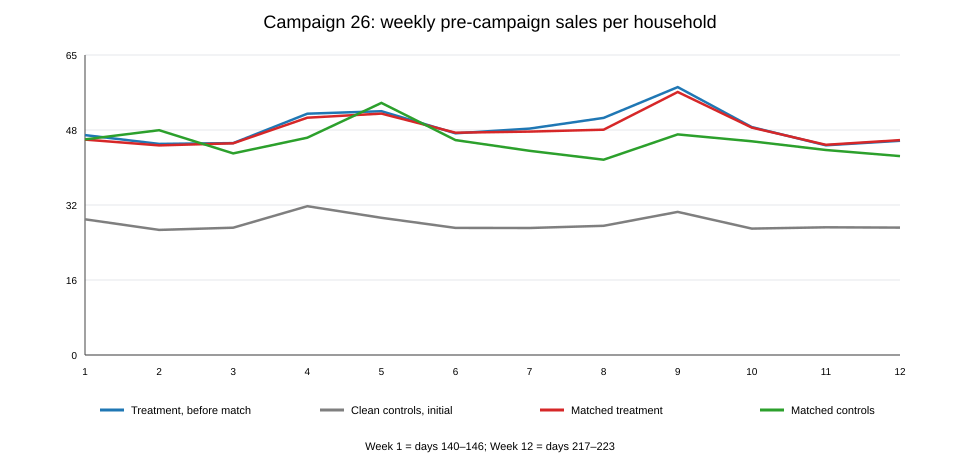

In [26]:
import html
import numpy as np
import pandas as pd
from IPython.display import SVG,display

weekly_cohorts=[('Treatment, before match',campaign26_treatment,'#1f77b4'),
 ('Clean controls, initial',campaign26_controls,'#7f7f7f'),
 ('Matched treatment',matched_treatment,'#d62728'),('Matched controls',matched_controls,'#2ca02c')]
trend_rows=[]
for w in range(1,13):
    col=f'week_{w:02d}_sales';row={'week':w,'day_range':f'{140+7*(w-1)}-{146+7*(w-1)}'}
    for label,cohort,_ in weekly_cohorts:
        row[f'{label}_mean']=float(cohort[col].mean()) if len(cohort) else np.nan
        row[f'{label}_median']=float(cohort[col].median()) if len(cohort) else np.nan
    trend_rows.append(row)
campaign26_weekly_trends=pd.DataFrame(trend_rows)

demographic_fields=('age_group','marital_status_code','income_group','homeowner_status','household_composition','household_size_group','kids_category')
demographic_cohorts=[('overlap_free_treatment',campaign26_treatment),('initial_window_clean_controls',campaign26_controls),
 ('matched_treatment',matched_treatment),('matched_controls',matched_controls)]
demog_rows=[]
for label,cohort in demographic_cohorts:
    row={'cohort':label,'households':len(cohort),'demographic_rows_n':int(cohort.has_demographics.sum()) if len(cohort) else 0,
         'demographic_rows_pct':round(100*float(cohort.has_demographics.mean()),1) if len(cohort) else np.nan}
    for f in demographic_fields:row[f'{f}_missing_pct']=round(100*float(cohort[f].isna().mean()),1) if len(cohort) else np.nan
    demog_rows.append(row)
campaign26_demographic_missingness=pd.DataFrame(demog_rows)
display(campaign26_weekly_trends)
display(campaign26_demographic_missingness)

def weekly_svg():
    width,height,left,right,top,bottom=980,470,85,900,55,355
    max_value=max([float(campaign26_weekly_trends[f'{label}_mean'].max()) for label,cohort,_ in weekly_cohorts if len(cohort)] or [1.])
    ymax=max_value*1.12 if max_value else 1.
    xmap=lambda w:left+(w-1)*(right-left)/11
    ymap=lambda v:bottom-v*(bottom-top)/ymax
    out=[f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="white"/>',
         '<text x="490" y="28" text-anchor="middle" font-size="18" font-family="Arial">Campaign 26: weekly pre-campaign sales per household</text>']
    for frac in (0,.25,.5,.75,1):
        val=ymax*frac;y=ymap(val)
        out.append(f'<line x1="{left}" y1="{y:.1f}" x2="{right}" y2="{y:.1f}" stroke="#e5e7eb"/>')
        out.append(f'<text x="{left-8}" y="{y+4:.1f}" text-anchor="end" font-size="10" font-family="Arial">{val:.0f}</text>')
    out.extend([f'<line x1="{left}" y1="{top}" x2="{left}" y2="{bottom}" stroke="#444"/>',f'<line x1="{left}" y1="{bottom}" x2="{right}" y2="{bottom}" stroke="#444"/>'])
    for w in range(1,13):out.append(f'<text x="{xmap(w):.1f}" y="{bottom+20}" text-anchor="middle" font-size="10" font-family="Arial">{w}</text>')
    for label,cohort,color in weekly_cohorts:
        if not len(cohort):continue
        vals=[float(campaign26_weekly_trends.loc[i,f'{label}_mean']) for i in range(12)]
        pts=' '.join(f'{xmap(i+1):.1f},{ymap(v):.1f}' for i,v in enumerate(vals))
        out.append(f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="2.5"/>')
    for i,(label,_,color) in enumerate(weekly_cohorts):
        x=100+i*220;out.append(f'<line x1="{x}" y1="410" x2="{x+24}" y2="410" stroke="{color}" stroke-width="3"/>')
        out.append(f'<text x="{x+31}" y="414" font-size="11" font-family="Arial">{html.escape(label)}</text>')
    out.append('<text x="490" y="450" text-anchor="middle" font-size="11" font-family="Arial">Week 1 = days 140–146; Week 12 = days 217–223</text></svg>')
    return ''.join(out)
campaign26_weekly_svg=weekly_svg()
display(SVG(campaign26_weekly_svg))


In [27]:
from IPython.display import Markdown,display
max_after=float(campaign26_balance.after_abs_smd.max()) if len(campaign26_balance) else float('inf')
worst=campaign26_balance.loc[campaign26_balance.after_abs_smd.idxmax(),'covariate'] if len(campaign26_balance) else 'none'
ret_clean=float(summary_matching.iloc[0].treated_retention_overlap_free_pct)
ret_original=float(summary_matching.iloc[0].treated_retention_original_assignment_pct)
matched_n=int(summary_matching.iloc[0].matched_treated_n)
if ret_clean<50:
    decision='Matching discards most overlap-free treated households; stop this design or change the target/design before outcome analysis.'
elif max_after>=.10:
    decision=f'Retention is {ret_clean:.1f}% of the overlap-free group, but the largest post-match absolute SMD is {max_after:.3f} ({worst}), above the 0.10 target. Do not proceed to outcome analysis without further design work.'
else:
    decision=f'The trial retains {ret_clean:.1f}% of overlap-free treated households and meets the 0.10 SMD target on listed features. Proceed only to further design review; this does not establish causal identification.'
finding=("## Campaign 26 matching-feasibility finding\n\n"
 f"The trial matched **{matched_n} of {len(campaign26_treatment)} overlap-free assigned households** ({ret_clean:.1f}%; {ret_original:.1f}% of the {len(campaign26_treated_all)} original assignments) to {matched_n} unique controls from {len(campaign26_controls)} clean controls. The unweighted 1:1 effective sample sizes are {summary_matching.iloc[0].matched_treated_ess:.0f} treated and {summary_matching.iloc[0].matched_control_ess:.0f} controls.\n\n"
 f"**Assessment:** {decision}\n\nAssignment is not confirmed exposure. Features stop on day 223, before the campaign, but the database does not record assignment timing, so pre-notification timing cannot be verified. No campaign-period or post-period value was used to choose features or the distance limit. The prior-assignment-count feature was zero for both groups and was excluded from distance as constant. Demographics were not used to drop households, and missingness remains a selection-bias limitation. Residual confounding and unmeasured targeting remain. No treatment effect, DiD or uplift was calculated.")
display(Markdown(finding))


## Campaign 26 matching-feasibility finding

The trial matched **277 of 282 overlap-free assigned households** (98.2%; 83.4% of the 332 original assignments) to 277 unique controls from 2078 clean controls. The unweighted 1:1 effective sample sizes are 277 treated and 277 controls.

**Assessment:** The trial retains 98.2% of overlap-free treated households and meets the 0.10 SMD target on listed features. Proceed only to further design review; this does not establish causal identification.

Assignment is not confirmed exposure. Features stop on day 223, before the campaign, but the database does not record assignment timing, so pre-notification timing cannot be verified. No campaign-period or post-period value was used to choose features or the distance limit. The prior-assignment-count feature was zero for both groups and was excluded from distance as constant. Demographics were not used to drop households, and missingness remains a selection-bias limitation. Residual confounding and unmeasured targeting remain. No treatment effect, DiD or uplift was calculated.

## Campaign 26 design audit before causal modelling

This audit checks timestamp availability, post-treatment cohort selection and alternative assignment cohorts. It uses only campaign metadata, assignment records and transaction history before Campaign 26's start (day 224). No campaign-period or post-campaign sales are queried for design selection.

The legacy “overlap-free” cohort removes households assigned to campaigns scheduled during or after Campaign 26's launch window. Since the assignment table has no event timestamp, this restriction may condition on post-assignment/post-treatment information. Alternative cohorts therefore include all 332 Campaign 26 assignments and all 2,168 households not assigned to Campaign 26, without removing households based on later campaign assignments.

An independent historical-trend diagnostic uses days 56–139, before the 12-week spending-slope feature window (days 140–223). It is not used to match or tune the cohort definition.


In [28]:
import pandas as pd
from sqlalchemy import text

time_column_query=text("""
    SELECT table_schema,table_name,column_name,data_type
    FROM information_schema.columns
    WHERE table_schema NOT IN ('information_schema','pg_catalog')
      AND (data_type IN ('date','time without time zone','time with time zone',
                         'timestamp without time zone','timestamp with time zone')
           OR column_name ~* '(assign|notif|send|created|updated|timestamp|datetime|event_time)')
    ORDER BY table_schema,table_name,ordinal_position
""")
campaign_schema_query=text("""
    SELECT table_schema,table_name,column_name,data_type
    FROM information_schema.columns
    WHERE table_schema NOT IN ('information_schema','pg_catalog')
      AND table_name ~* '(campaign|assign|notif|exposure|event|contact)'
    ORDER BY table_schema,table_name,ordinal_position
""")
all_campaign_query=text("""
    SELECT campaign_id,campaign_type,start_day,end_day
    FROM dbt_dev.dim_campaign ORDER BY start_day,campaign_id
""")
assignment_pair_query=text("""
    SELECT DISTINCT household_key,campaign_id
    FROM dbt_dev.bridge_household_campaign
""")
with engine.connect() as conn:
    assignment_time_columns=pd.read_sql_query(time_column_query,conn)
    campaign_related_schema=pd.read_sql_query(campaign_schema_query,conn)
    campaign26_calendar_all=pd.read_sql_query(all_campaign_query,conn)
    campaign26_assignment_pairs=pd.read_sql_query(assignment_pair_query,conn)

phase_windows={'pre_period':(196,223),'campaign_period':(224,264),'post_period':(265,292)}
campaign_phase_rows=[]
overlap_ids_by_phase={k:set() for k in phase_windows}
for _,c in campaign26_calendar_all.iterrows():
    cid=int(c.campaign_id)
    if cid==26: continue
    row={'other_campaign_id':cid,'campaign_type':c.campaign_type,'start_day':int(c.start_day),'end_day':int(c.end_day)}
    any_phase=False
    for phase,(lo,hi) in phase_windows.items():
        overlaps=int(c.start_day)<=hi and int(c.end_day)>=lo
        row[f'overlaps_{phase}']=overlaps
        if overlaps:overlap_ids_by_phase[phase].add(cid);any_phase=True
    if any_phase:campaign_phase_rows.append(row)
campaign26_phase_calendar=pd.DataFrame(campaign_phase_rows).sort_values('other_campaign_id').reset_index(drop=True)

assignment_set=set(map(tuple,campaign26_assignment_pairs[['household_key','campaign_id']].astype(int).to_numpy()))
assigned_ids=set(campaign26_treated_all.household_key.astype(int))
potential_control_ids=set(campaign26_initial_controls.household_key.astype(int))
phase_assignment_rows=[]
coassignment_by_campaign=[]
for phase,ids in overlap_ids_by_phase.items():
    treat_hits=set();control_hits=set()
    for hid,cid in assignment_set:
        if cid in ids:
            if hid in assigned_ids:treat_hits.add(hid)
            elif hid in potential_control_ids:control_hits.add(hid)
    phase_assignment_rows.append({'phase':phase,'overlapping_campaign_ids':', '.join(map(str,sorted(ids))) or 'none',
        'overlapping_campaign_count':len(ids),'assigned_campaign26_households_with_other_assignment':len(treat_hits),
        'candidate_unassigned_households_with_other_assignment':len(control_hits)})
    for cid in sorted(ids):
        treat_set={hid for hid,xid in assignment_set if xid==cid and hid in assigned_ids}
        ctrl_set={hid for hid,xid in assignment_set if xid==cid and hid in potential_control_ids}
        coassignment_by_campaign.append({'phase':phase,'other_campaign_id':cid,
            'c26_assigned_households_also_assigned':len(treat_set),
            'candidate_unassigned_households_also_assigned':len(ctrl_set)})
campaign26_phase_assignment_counts=pd.DataFrame(phase_assignment_rows)
campaign26_coassignment_by_campaign=pd.DataFrame(coassignment_by_campaign)
print('Candidate treatment assignments:',len(assigned_ids))
print('Potential comparisons:',len(potential_control_ids))
print('Window-clean treatment/comparison:',len(campaign26_treatment),len(campaign26_controls))
print('Other campaign schedules overlapping pre/during/post:',{k:sorted(v) for k,v in overlap_ids_by_phase.items()})
display(campaign_related_schema)
display(assignment_time_columns)
display(campaign26_phase_calendar)
display(campaign26_phase_assignment_counts)
display(campaign26_coassignment_by_campaign)


Candidate treatment assignments: 332
Potential comparisons: 2168
Window-clean treatment/comparison: 282 2078
Other campaign schedules overlapping pre/during/post: {'pre_period': [], 'campaign_period': [27, 28], 'post_period': [27, 28, 29]}


,table_schema,table_name,column_name,data_type
0,dbt_dev,bridge_coupon_product_campaign,coupon_upc,bigint
1,dbt_dev,bridge_coupon_product_campaign,product_id,integer
2,dbt_dev,bridge_coupon_product_campaign,campaign_id,integer
3,dbt_dev,bridge_household_campaign,household_key,integer
4,dbt_dev,bridge_household_campaign,campaign_id,integer
5,dbt_dev,dim_campaign,campaign_id,integer
6,dbt_dev,dim_campaign,campaign_type,text
7,dbt_dev,dim_campaign,start_day,integer
8,dbt_dev,dim_campaign,end_day,integer
9,dbt_dev,stg_campaign_desc,campaign_id,integer


,table_schema,table_name,column_name,data_type


,other_campaign_id,campaign_type,start_day,end_day,overlaps_pre_period,overlaps_campaign_period,overlaps_post_period
0,27,TypeC,237,300,False,True,True
1,28,TypeB,259,320,False,True,True
2,29,TypeB,281,334,False,False,True


,phase,overlapping_campaign_ids,overlapping_campaign_count,assigned_campaign26_households_with_other_assignment,candidate_unassigned_households_with_other_assignment
0,pre_period,none,0,0,0
1,campaign_period,"27, 28",2,22,3
2,post_period,"27, 28, 29",3,50,90


,phase,other_campaign_id,c26_assigned_households_also_assigned,candidate_unassigned_households_also_assigned
0,campaign_period,27,11,1
1,campaign_period,28,15,2
2,post_period,27,11,1
3,post_period,28,15,2
4,post_period,29,31,87


In [29]:
import math
import numpy as np
import pandas as pd

# Alternative definitions contrast an assignment estimand with the legacy future-overlap restriction.
pre_overlap_ids=overlap_ids_by_phase['pre_period']
pre_overlap_households={hid for hid,cid in assignment_set if cid in pre_overlap_ids}
preperiod_treatment=campaign26_treated_all.loc[~campaign26_treated_all.household_key.astype(int).isin(pre_overlap_households)].copy().reset_index(drop=True)
preperiod_controls=campaign26_initial_controls.loc[~campaign26_initial_controls.household_key.astype(int).isin(pre_overlap_households)].copy().reset_index(drop=True)

def _dist(left,right):
    ln=np.einsum('ij,ij->i',left,left);rn=np.einsum('ij,ij->i',right,right)
    d2=ln[:,None]+rn[None,:]-2*left@right.T
    np.maximum(d2,0,out=d2)
    return np.sqrt(d2)

def _smd(a,b):
    a=pd.Series(a,dtype=float);b=pd.Series(b,dtype=float)
    if not len(a) or not len(b):return np.nan
    sa=float(a.std(ddof=1)) if len(a)>1 else 0.;sb=float(b.std(ddof=1)) if len(b)>1 else 0.
    den=math.sqrt((sa*sa+sb*sb)/2)
    return ((float(a.mean())-float(b.mean()))/den) if den else (0. if float(a.mean())==float(b.mean()) else np.inf)

def _cohort_match(treated,controls):
    treated=treated.reset_index(drop=True);controls=controls.reset_index(drop=True)
    cmean=controls[distance_features].mean()
    csd=controls[distance_features].std(ddof=1).replace(0,1).fillna(1)
    cx=((controls[distance_features]-cmean)/csd).to_numpy(float)
    tx=((treated[distance_features]-cmean)/csd).to_numpy(float)
    cd=_dist(cx,cx)
    ca=controls.active_recent28.to_numpy()
    cd[ca[:,None]!=ca[None,:]]=np.inf;np.fill_diagonal(cd,np.inf)
    kth=np.partition(cd,4,axis=1)[:,4]
    finite=kth[np.isfinite(kth)]
    cal=float(np.quantile(finite,.95)) if len(finite) else 0.
    td=_dist(tx,cx)
    ta=treated.active_recent28.to_numpy()
    td[ta[:,None]!=ca[None,:]]=np.inf
    ti,ci=np.where(np.isfinite(td)&(td<=cal))
    order=np.argsort(td[ti,ci],kind='mergesort')
    used_t=set();used_c=set();mt=[];mc=[]
    for p in order:
        i,j=int(ti[p]),int(ci[p])
        if i not in used_t and j not in used_c:
            used_t.add(i);used_c.add(j);mt.append(i);mc.append(j)
    mtf=treated.iloc[mt].copy().reset_index(drop=True)
    mcf=controls.iloc[mc].copy().reset_index(drop=True)
    smds_before=[abs(_smd(treated[col],controls[col])) for _,col in balance_specs]
    smds_after=[abs(_smd(mtf[col],mcf[col])) for _,col in balance_specs] if len(mtf) else [np.nan]
    nearest_fifth=np.partition(td,4,axis=1)[:,4] if len(treated) else np.array([])
    support_pct=round(100*float((nearest_fifth<=cal).mean()),1) if len(nearest_fifth) else 0.
    return mtf,mcf,{'treated_n':len(treated),'comparison_n':len(controls),'matched_treated_n':len(mtf),
        'matched_control_n':len(mcf),'unmatched_treated_n':len(treated)-len(mtf),
        'unmatched_control_n':len(controls)-len(mcf),
        'treated_retention_pct':round(100*len(mtf)/len(treated),1) if len(treated) else 0.,
        'retention_of_all_332_assignments_pct':round(100*len(mtf)/len(campaign26_treated_all),1),
        'baseline_max_abs_smd':round(float(np.nanmax(smds_before)),3),
        'post_match_max_abs_smd':round(float(np.nanmax(smds_after)),3) if len(mtf) else np.nan,
        'fifth_neighbor_support_pct':support_pct,'control_5nn_caliper':round(cal,4)}

cohort_definitions=[
    ('Full assignment vs all candidate-unassigned','Assignment effect in observed promo environment; no future-overlap filter',campaign26_treated_all,campaign26_initial_controls),
    ('Full assignment vs window-clean controls','Asymmetric: all treated, controls future-overlap filtered',campaign26_treated_all,campaign26_controls),
    ('Overlap-free treatment vs all candidate-unassigned','Treatment-only future-overlap selection',campaign26_treatment,campaign26_initial_controls),
    ('Overlap-free treatment vs window-clean controls','Legacy dual future-overlap filter',campaign26_treatment,campaign26_controls),
    ('Pre-period schedule-clean vs pre-period schedule-clean','Filters assignments to campaigns dated in pre-window only; timestamps still unknown',preperiod_treatment,preperiod_controls),
]
alternative_matches={};alt_rows=[]
for label,interpretation,t,c in cohort_definitions:
    mtf,mcf,metrics=_cohort_match(t,c)
    alternative_matches[label]=(mtf,mcf)
    alt_rows.append({'cohort_definition':label,'interpretation':interpretation,
        'other_campaigns_overlapping_preperiod':len(pre_overlap_ids),**metrics})
campaign26_alternative_cohorts=pd.DataFrame(alt_rows)

baseline_rows=[]
baseline_pairs=[
 ('Full assignment vs all unassigned',campaign26_treated_all,campaign26_initial_controls),
 ('Full assignment vs clean controls',campaign26_treated_all,campaign26_controls),
 ('Overlap-free vs all unassigned',campaign26_treatment,campaign26_initial_controls),
 ('Overlap-free vs clean controls',campaign26_treatment,campaign26_controls),
]
for label,t,c in baseline_pairs:
    for variable in ('sales_recent28','baskets_recent28','active_recent28','recency_days_84'):
        baseline_rows.append({'comparison':label,'feature':variable,'treated_n':len(t),'control_n':len(c),
            'treated_mean':float(t[variable].mean()),'control_mean':float(c[variable].mean()),
            'signed_smd':_smd(t[variable],c[variable])})
campaign26_alternative_baseline=pd.DataFrame(baseline_rows)
display(campaign26_alternative_cohorts)
display(campaign26_alternative_baseline)


,cohort_definition,interpretation,other_campaigns_overlapping_preperiod,treated_n,comparison_n,matched_treated_n,matched_control_n,unmatched_treated_n,unmatched_control_n,treated_retention_pct,retention_of_all_332_assignments_pct,baseline_max_abs_smd,post_match_max_abs_smd,fifth_neighbor_support_pct,control_5nn_caliper
0,Full assignment vs all candidate-unassigned,Assignment effect in observed promo environmen...,0,332,2168,325,325,7,1843,97.9,97.9,0.680,0.083,90.4,0.9961
1,Full assignment vs window-clean controls,"Asymmetric: all treated, controls future-overl...",0,332,2078,325,325,7,1753,97.9,97.9,0.714,0.086,90.4,0.9968
2,Overlap-free treatment vs all candidate-unassi...,Treatment-only future-overlap selection,0,282,2168,277,277,5,1891,98.2,83.4,0.643,0.086,90.1,0.9961
3,Overlap-free treatment vs window-clean controls,Legacy dual future-overlap filter,0,282,2078,277,277,5,1801,98.2,83.4,0.671,0.097,90.1,0.9968
4,Pre-period schedule-clean vs pre-period schedu...,Filters assignments to campaigns dated in pre-...,0,332,2168,325,325,7,1843,97.9,97.9,0.680,0.083,90.4,0.9961


,comparison,feature,treated_n,control_n,treated_mean,control_mean,signed_smd
0,Full assignment vs all unassigned,sales_recent28,332,2168,208.319699,117.320683,0.515349
1,Full assignment vs all unassigned,baskets_recent28,332,2168,7.153614,4.282288,0.457793
2,Full assignment vs all unassigned,active_recent28,332,2168,0.942771,0.765221,0.519230
3,Full assignment vs all unassigned,recency_days_84,332,2168,7.804217,20.017528,-0.556982
4,Full assignment vs clean controls,sales_recent28,332,2078,208.319699,112.970794,0.543504
5,Full assignment vs clean controls,baskets_recent28,332,2078,7.153614,4.169394,0.479402
6,Full assignment vs clean controls,active_recent28,332,2078,0.942771,0.755534,0.541740
7,Full assignment vs clean controls,recency_days_84,332,2078,7.804217,20.662656,-0.580034
8,Overlap-free vs all unassigned,sales_recent28,282,2168,198.049326,117.320683,0.460257
9,Overlap-free vs all unassigned,baskets_recent28,282,2168,7.014184,4.282288,0.430488


,contrast,treated_n,control_n,treated_mean_slope,control_mean_slope,slope_smd
0,Full assignment vs unassigned,332,2168,-0.002805,0.114319,-0.668471
1,Full assignment matched,325,325,-0.002542,0.193373,-1.052585
2,Overlap-free vs window-clean,282,2078,-0.003239,0.111281,-0.654797
3,Overlap-free matched,277,277,-0.003144,0.182551,-1.002172


,week,day_range,Full assignment_mean,Full assignment_median,All candidate-unassigned_mean,All candidate-unassigned_median,Full assignment matched_mean,Full assignment matched_median,Matched candidate-unassigned_mean,Matched candidate-unassigned_median
0,1,56-62,47.503735,25.225,7.856822,0.00,48.092215,25.91,11.819108,0.00
1,2,63-69,62.876024,39.435,11.479972,0.00,62.267846,38.68,15.367692,0.00
2,3,70-76,54.170693,38.725,14.887297,0.00,53.937877,38.52,24.849508,0.00
3,4,77-83,56.547199,37.605,15.696301,0.00,55.992215,37.08,22.351631,0.00
4,5,84-90,56.667892,38.770,17.004054,0.00,55.505354,38.68,29.595077,0.00
5,6,91-97,57.245482,37.820,20.862177,0.00,57.258738,37.25,32.400738,1.30
6,7,98-104,58.184036,36.915,26.462860,0.00,57.960923,36.63,37.238062,7.83
7,8,105-111,52.052139,31.115,27.981591,0.00,51.710800,30.65,41.410000,17.29
8,9,112-118,58.112861,33.685,27.965498,2.49,56.668092,33.83,47.201077,30.37
9,10,119-125,53.077651,31.235,27.011776,0.00,53.432954,31.66,47.199969,19.14


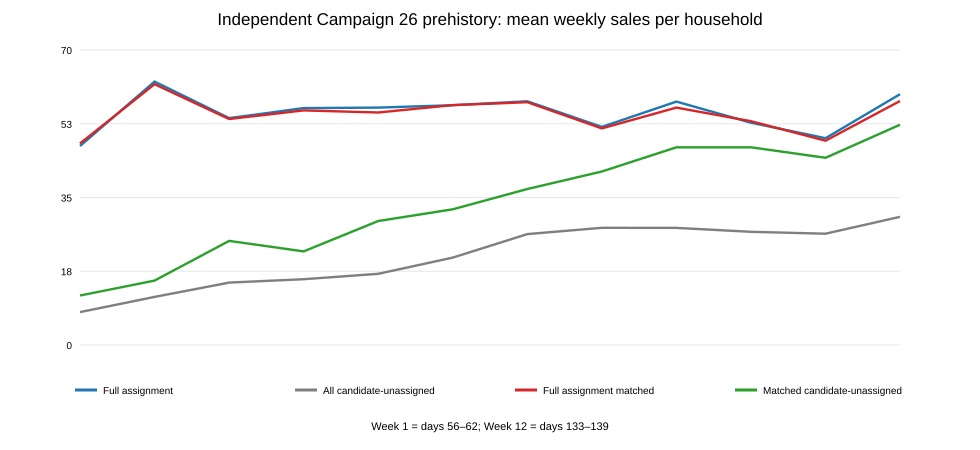

In [30]:
import numpy as np
import pandas as pd
from sqlalchemy import text
from IPython.display import SVG,display

# Independent history: days 56-139, 84 days earlier than every matching feature window.
history_week_query=text("""
    SELECT household_key,((transaction_day-56)/7+1)::integer AS week_number,
           SUM(sales_value)::numeric AS weekly_sales
    FROM dbt_dev.fct_sales WHERE transaction_day BETWEEN 56 AND 139
    GROUP BY household_key,((transaction_day-56)/7+1)::integer
    ORDER BY household_key,week_number
""")
with engine.connect() as conn:
    historical_weekly_long=pd.read_sql_query(history_week_query,conn)
history_wide=(historical_weekly_long.pivot(index='household_key',columns='week_number',values='weekly_sales')
    .reindex(columns=range(1,13),fill_value=0).fillna(0.0))
history_cols=[f'hist_week_{i:02d}' for i in range(1,13)]
history_wide.columns=history_cols
historical_household_features=campaign26_features[['household_key','assigned_campaign26','other_overlapping_assignment']].merge(
    history_wide,how='left',left_on='household_key',right_index=True)
historical_household_features[history_cols]=historical_household_features[history_cols].fillna(0.0)
hx=np.arange(1,13,dtype=float);hxc=hx-hx.mean()
hlogs=np.log1p(historical_household_features[history_cols].to_numpy(float))
historical_household_features['independent_12w_log_sales_slope']=((hlogs-hlogs.mean(axis=1,keepdims=True))@hxc)/np.sum(hxc**2)
hist_map=historical_household_features.set_index('household_key')

history_groups={
 'Full assignment':set(campaign26_treated_all.household_key.astype(int)),
 'All candidate-unassigned':set(campaign26_initial_controls.household_key.astype(int)),
 'Full assignment matched':set(alternative_matches['Full assignment vs all candidate-unassigned'][0].household_key.astype(int)),
 'Matched candidate-unassigned':set(alternative_matches['Full assignment vs all candidate-unassigned'][1].household_key.astype(int)),
 'Overlap-free treatment':set(campaign26_treatment.household_key.astype(int)),
 'Window-clean controls':set(campaign26_controls.household_key.astype(int)),
 'Overlap-free matched':set(alternative_matches['Overlap-free treatment vs window-clean controls'][0].household_key.astype(int)),
 'Window-clean matched':set(alternative_matches['Overlap-free treatment vs window-clean controls'][1].household_key.astype(int)),
}
hist_slope_rows=[]
for contrast,t_name,c_name in [
 ('Full assignment vs unassigned','Full assignment','All candidate-unassigned'),
 ('Full assignment matched','Full assignment matched','Matched candidate-unassigned'),
 ('Overlap-free vs window-clean','Overlap-free treatment','Window-clean controls'),
 ('Overlap-free matched','Overlap-free matched','Window-clean matched')]:
    tvals=hist_map.loc[list(history_groups[t_name]),'independent_12w_log_sales_slope']
    cvals=hist_map.loc[list(history_groups[c_name]),'independent_12w_log_sales_slope']
    hist_slope_rows.append({'contrast':contrast,'treated_n':len(tvals),'control_n':len(cvals),
        'treated_mean_slope':float(tvals.mean()),'control_mean_slope':float(cvals.mean()),
        'slope_smd':_smd(tvals,cvals)})
campaign26_independent_trend_balance=pd.DataFrame(hist_slope_rows)

weekly_trend_rows=[]
for w in range(1,13):
    col=f'hist_week_{w:02d}';row={'week':w,'day_range':f'{56+7*(w-1)}-{62+7*(w-1)}'}
    for label in ('Full assignment','All candidate-unassigned','Full assignment matched','Matched candidate-unassigned'):
        vals=hist_map.loc[list(history_groups[label]),col]
        row[f'{label}_mean']=float(vals.mean());row[f'{label}_median']=float(vals.median())
    weekly_trend_rows.append(row)
campaign26_independent_weekly_trends=pd.DataFrame(weekly_trend_rows)
display(campaign26_independent_trend_balance)
display(campaign26_independent_weekly_trends)

def historical_svg():
    w,h,l,r,t,b=980,450,80,900,50,345
    labels=('Full assignment','All candidate-unassigned','Full assignment matched','Matched candidate-unassigned')
    colors=('#1f77b4','#7f7f7f','#d62728','#2ca02c')
    maxy=max(float(campaign26_independent_weekly_trends[f'{x}_mean'].max()) for x in labels)*1.12
    xm=lambda i:l+i*(r-l)/11;ym=lambda v:b-v*(b-t)/maxy
    parts=[f'<svg xmlns="http://www.w3.org/2000/svg" width="{w}" height="{h}" viewBox="0 0 {w} {h}">',
      '<rect width="100%" height="100%" fill="white"/>',
      '<text x="490" y="25" text-anchor="middle" font-size="17" font-family="Arial">Independent Campaign 26 prehistory: mean weekly sales per household</text>']
    for q in (0,.25,.5,.75,1):
        v=maxy*q;y=ym(v);parts.append(f'<line x1="{l}" y1="{y:.1f}" x2="{r}" y2="{y:.1f}" stroke="#e5e7eb"/>')
        parts.append(f'<text x="{l-8}" y="{y+4:.1f}" text-anchor="end" font-size="10" font-family="Arial">{v:.0f}</text>')
    for j,(label,color) in enumerate(zip(labels,colors)):
        vals=campaign26_independent_weekly_trends[f'{label}_mean'].to_list()
        pts=' '.join(f'{xm(i):.1f},{ym(v):.1f}' for i,v in enumerate(vals))
        parts.append(f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="2.4"/>')
        x=75+j*220;parts.append(f'<line x1="{x}" y1="390" x2="{x+22}" y2="390" stroke="{color}" stroke-width="3"/>')
        parts.append(f'<text x="{x+28}" y="394" font-size="10" font-family="Arial">{label}</text>')
    parts.append('<text x="490" y="430" text-anchor="middle" font-size="11" font-family="Arial">Week 1 = days 56–62; Week 12 = days 133–139</text></svg>')
    return ''.join(parts)
campaign26_independent_trend_svg=historical_svg()
display(SVG(campaign26_independent_trend_svg))


In [31]:
campaign26_alternative_cohorts

,cohort_definition,interpretation,other_campaigns_overlapping_preperiod,treated_n,comparison_n,matched_treated_n,matched_control_n,unmatched_treated_n,unmatched_control_n,treated_retention_pct,retention_of_all_332_assignments_pct,baseline_max_abs_smd,post_match_max_abs_smd,fifth_neighbor_support_pct,control_5nn_caliper
0,Full assignment vs all candidate-unassigned,Assignment effect in observed promo environmen...,0,332,2168,325,325,7,1843,97.9,97.9,0.680,0.083,90.4,0.9961
1,Full assignment vs window-clean controls,"Asymmetric: all treated, controls future-overl...",0,332,2078,325,325,7,1753,97.9,97.9,0.714,0.086,90.4,0.9968
2,Overlap-free treatment vs all candidate-unassi...,Treatment-only future-overlap selection,0,282,2168,277,277,5,1891,98.2,83.4,0.643,0.086,90.1,0.9961
3,Overlap-free treatment vs window-clean controls,Legacy dual future-overlap filter,0,282,2078,277,277,5,1801,98.2,83.4,0.671,0.097,90.1,0.9968
4,Pre-period schedule-clean vs pre-period schedu...,Filters assignments to campaigns dated in pre-...,0,332,2168,325,325,7,1843,97.9,97.9,0.680,0.083,90.4,0.9961


### Interpretation and recommendation

**Decision: REVISE. Do not proceed to causal estimation with the current matched design.** Matching on the available recent features produces good measured balance, but the independent earlier trend diagnostic shows substantial divergence, and assignment timing is unavailable. The audit used no Campaign 26 or later-period sales outcomes to select a cohort or tune matching.

#### Timing and assignment

The project source search and PostgreSQL catalog query found no campaign assignment, notification, sent, dispatch or exposure timestamp fields. `dbt_dev.bridge_household_campaign` exposes household and campaign IDs; `dbt_dev.dim_campaign` exposes scheduled start/end days. Therefore campaign start day 224 cannot be treated as the assignment date. Purchase/activity features in days 140-223, including the recent 28-day windows and spending slope used for matching, precede launch but are not verified to precede assignment or notification. They could be affected if households were contacted or changed behaviour before launch.

#### Other campaign schedules and overlap filtering

| Campaign 26 phase | Days | Other campaign schedules overlapping | Distinct C26 assignees co-assigned | Distinct C26-unassigned households co-assigned |
|---|---:|---|---:|---:|
| Pre-period | 196-223 | None (0) | 0 | 0 |
| Campaign period | 224-264 | 27 and 28 (2) | 22 | 3 |
| Post-period | 265-292 | 27, 28 and 29 (3) | 50 | 90 |

Campaign 27 is scheduled for days 237-300, Campaign 28 for 259-320, and Campaign 29 for 281-334. These are schedule overlaps, not dated assignment events. The legacy complete-window rule excludes 50/332 assigned households (15.1%) and 90/2,168 otherwise eligible comparisons (4.2%). It retains 282 treated and 2,078 controls. Campaign-specific coassignment counts can overlap across campaigns; households were counted once per phase using distinct household-campaign pairs. Because all excluded campaigns are scheduled during or after Campaign 26 launch and assignment times are missing, this restriction may select on post-assignment information. Whether it actually does is not verifiable.

#### Cohort sensitivity (same pre-treatment matching procedure)

| Cohort definition | Starting treated / controls | Matched pairs | Treated retained | Of original 332 retained | Max abs SMD before / after | Independent trend slope SMD after match |
|---|---:|---:|---:|---:|---:|---:|
| Full assignment vs all C26-unassigned | 332 / 2,168 | 325 | 97.9% | 97.9% | 0.680 / 0.083 | -1.053 |
| Full assignment vs window-clean controls | 332 / 2,078 | 325 | 97.9% | 97.9% | 0.714 / 0.086 | Not separately tabulated |
| Overlap-free treatment vs all C26-unassigned | 282 / 2,168 | 277 | 98.2% | 83.4% | 0.643 / 0.086 | -1.003 |
| Legacy overlap-free vs window-clean | 282 / 2,078 | 277 | 98.2% | 83.4% | 0.671 / 0.097 | -1.003 |

The pre-period schedule-clean definition is identical to the full assignment cohort: no other campaign schedule overlaps days 196-223. Full-cohort pre-match recent baselines remain different: recent 28-day sales average 208.32 vs 117.32 (SMD 0.515), basket frequency 7.15 vs 4.28 (0.458), active-household rate 94.3% vs 76.5% (0.519), and recency 7.8 vs 20.0 days (-0.557). The 325 matched pairs reduce the maximum absolute SMD across the 14 matching covariates to 0.083. This balance does not resolve the trend diagnostic below.

#### Independent pre-campaign trend diagnostic

The separate 12-week period, days 56-139, predates the matching feature windows and was not used to match or tune the design. Its household-level log(1 + weekly sales) slope SMD is -0.668 for all 332 assignees versus all 2,168 non-assignees. After matching the full cohort, it is -1.053 (treated mean slope -0.0025; control 0.1934). Weekly matched control spending rises from about 11.82 in days 56-62 to 52.59 in days 133-139, while treated means remain roughly 48-58. Thus the independent historical trajectory is substantially different and matching on recent levels did not remove it. This is adverse evidence for a parallel-trends design, not a test that proves or disproves the assumption.

#### What is known and what remains untestable

- **Verified in available data:** 332 distinct C26 assignees and 2,168 households not assigned to C26; campaign schedule windows; 0 schedule overlaps in the pre-window; unique household counts are computed from distinct assignment pairs; historical transaction data exist for days 56-139 and the evaluation dates are inside the previously validated day 1-711 range; all zero-purchase weeks in the historical panel are retained as zero.
- **Not verified:** assignment or notification timing, actual campaign receipt/viewing/redemption as exposure, whether C26 assignment changed later campaign assignment, and whether the observed bridge contains the full intended assignment history.
- **Untestable from these data alone:** absence of unmeasured targeting/confounding, consistency of assignment/exposure, no spillovers/interference, and parallel untreated trends. Demographic fields have known missingness and cannot guarantee exchangeability.

#### Recommended target for any later design work

Use the **full 332 assigned households versus all 2,168 households not assigned to C26**, with no exclusion based on campaigns assigned during or after C26. The defensible target would be an assignment-based effect in the observed promotion portfolio, including naturally occurring coassignments; it is not an isolated exposure effect and assignment is not randomized. Treat the 282/2,078 overlap-filtered cohort only as a sensitivity analysis. Despite 325 pairs and excellent balance on the 14 matched features, the large independent trend imbalance means the current design is **not ready for DiD or uplift**. Resolve assignment timing and improve/justify pretrend comparability using only confirmed pre-assignment information, or reconsider the design/estimand before causal modelling. No effect was estimated.


## Descriptive campaign analysis

This analysis describes campaign schedules, household assignments, recorded coupon redemptions, observed sales and shopping frequency. Assignment is a targeting record; redemption is a recorded coupon-use event; neither proves that a household saw or received a campaign. Household exposure is not observed in this dataset.

The Campaign 26 spending comparison uses the 332 households assigned to Campaign 26 and the 2,168 purchasing households not assigned to it. The latter are an observational reference group, not randomized controls; 1,252 were assigned to other campaigns and 916 were never campaign-assigned. Household-period aggregates are calculated in PostgreSQL and include zero-purchase households. Only the resulting 7,500 household-period rows are brought into Python for summaries and charts.

Windows use scheduled relative days: pre 196-223 (28 days), Campaign 26 224-264 (41 days), and post 265-292 (28 days). For comparability, spending and basket frequency are also expressed per household per 28-day equivalent: observed window totals multiplied by 28 / window days. This is a descriptive daily-rate normalization; it is not an estimate of campaign impact. No matching, uplift or difference-in-differences is performed.


In [32]:
phase3_campaign_dimensions=fetch_campaign_dimensions(engine)
phase3_assignment_pairs=fetch_assignment_pairs(engine)
phase3_redemption_events=fetch_redemption_events(engine)
phase3_campaign_overview=build_campaign_overview(
    phase3_campaign_dimensions,phase3_assignment_pairs,phase3_redemption_events
)
display(phase3_campaign_overview.drop(columns=[
    'share_assigned_also_assigned_any','share_assigned_schedule_overlap'
]))


,campaign_id,campaign_type,start_day,end_day,duration_days,assigned_households,households_also_assigned_any,households_also_assigned_schedule_overlap,recorded_redemption_events,unique_redeemers,share_assigned_also_assigned_any_pct,share_assigned_schedule_overlap_pct
0,1,TypeB,346,383,38,13,13,11,1,1,100.0,84.6
1,2,TypeB,351,383,33,48,48,36,5,2,100.0,75.0
2,3,TypeC,356,412,57,12,12,12,2,2,100.0,100.0
3,4,TypeB,372,404,33,81,81,36,11,6,100.0,44.4
4,5,TypeB,377,411,35,166,164,78,13,8,98.8,47.0
5,6,TypeC,393,425,33,65,65,61,1,1,100.0,93.8
6,7,TypeB,398,432,35,198,195,182,7,5,98.5,91.9
7,8,TypeA,412,460,49,1076,1009,308,372,158,93.8,28.6
8,9,TypeB,435,467,33,176,170,138,43,20,96.6,78.4
9,10,TypeB,463,495,33,123,123,78,15,10,100.0,63.4


### Campaign overview definitions

Assigned-household counts use distinct household-campaign pairs. “Also assigned” counts distinct households with a separate campaign assignment, regardless of its timing. “Schedule-overlap co-assigned” is the subset with another campaign whose scheduled relative-day range intersects the focal campaign dates. Redemptions count recorded coupon redemption events and unique redeemers; they are not an exposure measure.

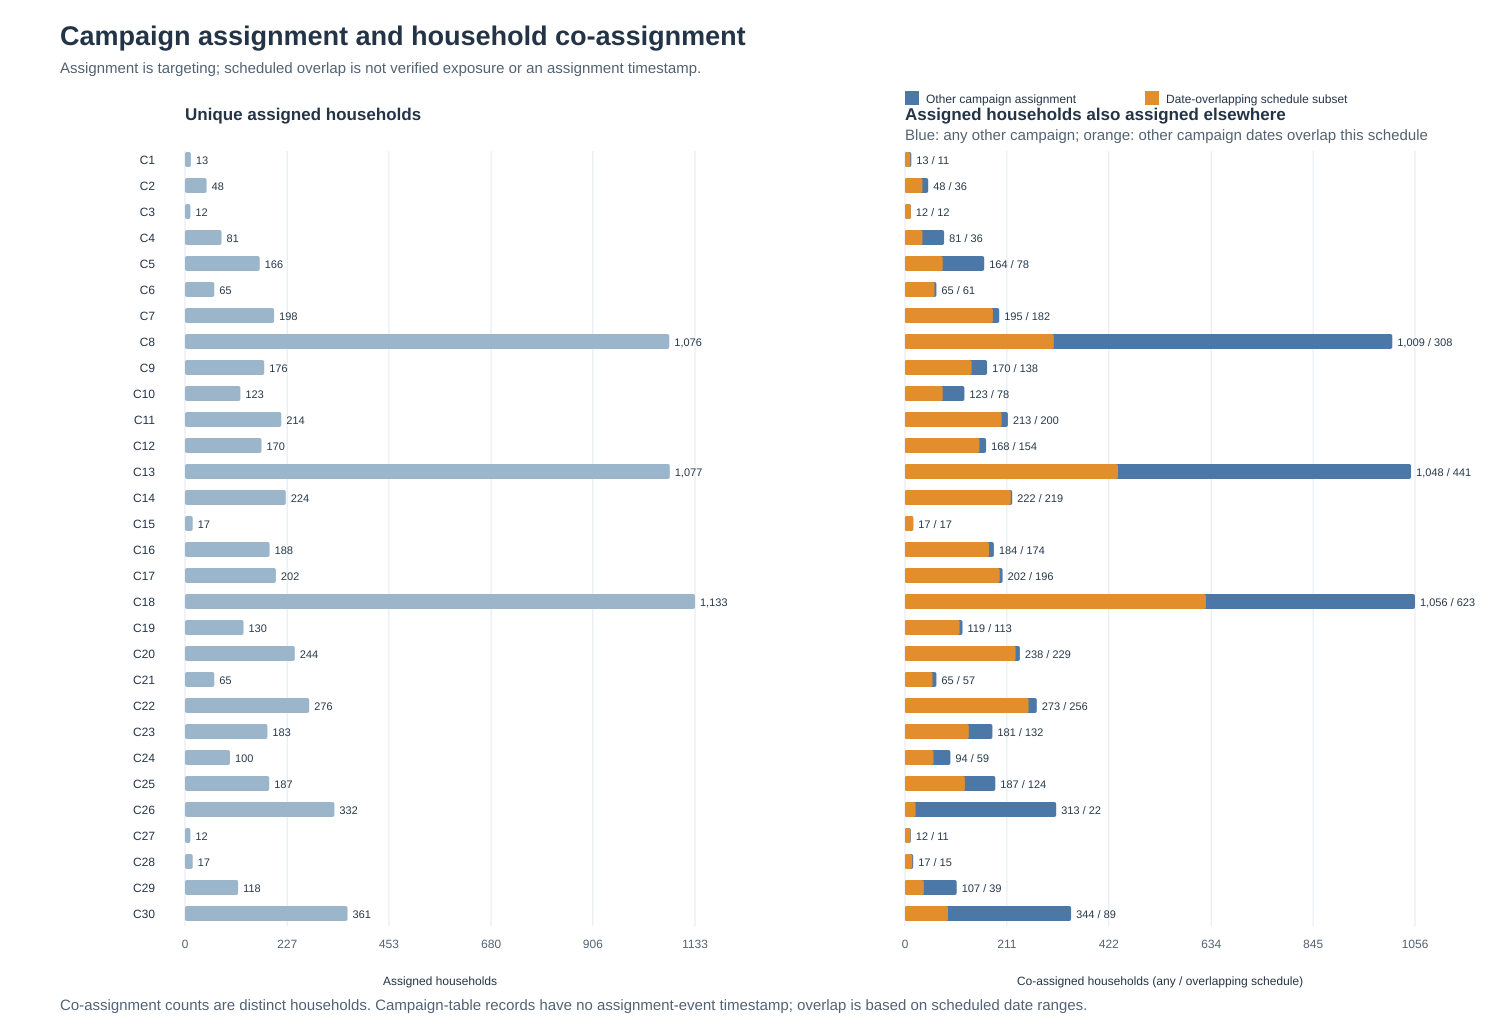

Saved vector chart: docs/figures/campaign_assignment_overlap.svg


In [33]:
from IPython.display import SVG,display

phase3_assignment_svg=campaign_assignment_overlap_svg(phase3_campaign_overview)
phase3_assignment_path=save_svg(
    phase3_assignment_svg,project_root/'docs'/'figures'/'campaign_assignment_overlap.svg'
)
display(SVG(phase3_assignment_svg))
print('Saved vector chart:',phase3_assignment_path.relative_to(project_root).as_posix())


### Campaign 26 descriptive windows and units

Recorded `sales_value` is summed at household-window level from `dbt_dev.fct_sales`; shopping frequency is distinct baskets per household. The SQL starts from all 2,500 purchasing households and left-joins window activity, so households with no purchase in a window remain in the distribution with zero spending and zero baskets. The non-assigned group may include other campaign assignments and is not a control group.

The during-campaign window is 41 days versus 28 days for pre and post. The chart and normalized summary use each household's observed window total multiplied by 28 / window days. Reported units are recorded sales-value dollars per household per 28-day equivalent and baskets per household per 28-day equivalent. Raw actual-window means are also retained in the table. Normalization is arithmetic only and does not adjust for seasonality, other campaigns or customer exposure.


In [34]:
phase3_c26_calendar=phase3_campaign_dimensions.loc[
    phase3_campaign_dimensions.campaign_id==26
].iloc[0]
phase3_c26_windows=build_campaign_windows(
    int(phase3_c26_calendar.start_day),int(phase3_c26_calendar.end_day),
    pre_days=28,post_days=28
)
phase3_c26_household_period=fetch_campaign26_household_periods(
    engine,phase3_c26_windows,campaign_id=26
)
phase3_c26_household_period,phase3_c26_descriptive_summary=summarize_household_periods(
    phase3_c26_household_period,target_days=28
)
display(phase3_c26_descriptive_summary)
print('Household-period records summarized:',len(phase3_c26_household_period))


,assignment_group,period,days,households_including_zeros,active_households,zero_purchase_households,active_rate_pct,mean_spend_actual_window_per_household,mean_spend_per_28d_equivalent,p10_spend_per_28d_equivalent,p25_spend_per_28d_equivalent,p50_spend_per_28d_equivalent,p75_spend_per_28d_equivalent,p90_spend_per_28d_equivalent,mean_baskets_actual_window_per_household,mean_baskets_per_28d_equivalent,median_baskets_per_28d_equivalent
0,Assigned to Campaign 26,Pre,28,332,313,19,94.3,208.32,208.32,11.79,64.08,153.06,318.00,451.91,7.15,7.15,6.00
1,Not assigned to Campaign 26,Pre,28,2168,1659,509,76.5,117.32,117.32,0.00,3.22,62.52,161.47,316.40,4.28,4.28,3.00
2,Assigned to Campaign 26,Campaign,41,332,316,16,95.2,323.81,221.14,26.65,90.34,164.50,283.61,480.85,10.53,7.19,5.46
3,Not assigned to Campaign 26,Campaign,41,2168,1785,383,82.3,181.29,123.81,0.00,10.80,65.19,171.72,337.15,6.26,4.27,2.73
4,Assigned to Campaign 26,Post,28,332,311,21,93.7,216.63,216.63,20.10,70.01,162.19,292.49,483.86,6.97,6.97,5.00
5,Not assigned to Campaign 26,Post,28,2168,1666,502,76.8,128.00,128.00,0.00,4.60,61.25,179.88,355.39,4.27,4.27,2.00


Household-period records summarized: 7500


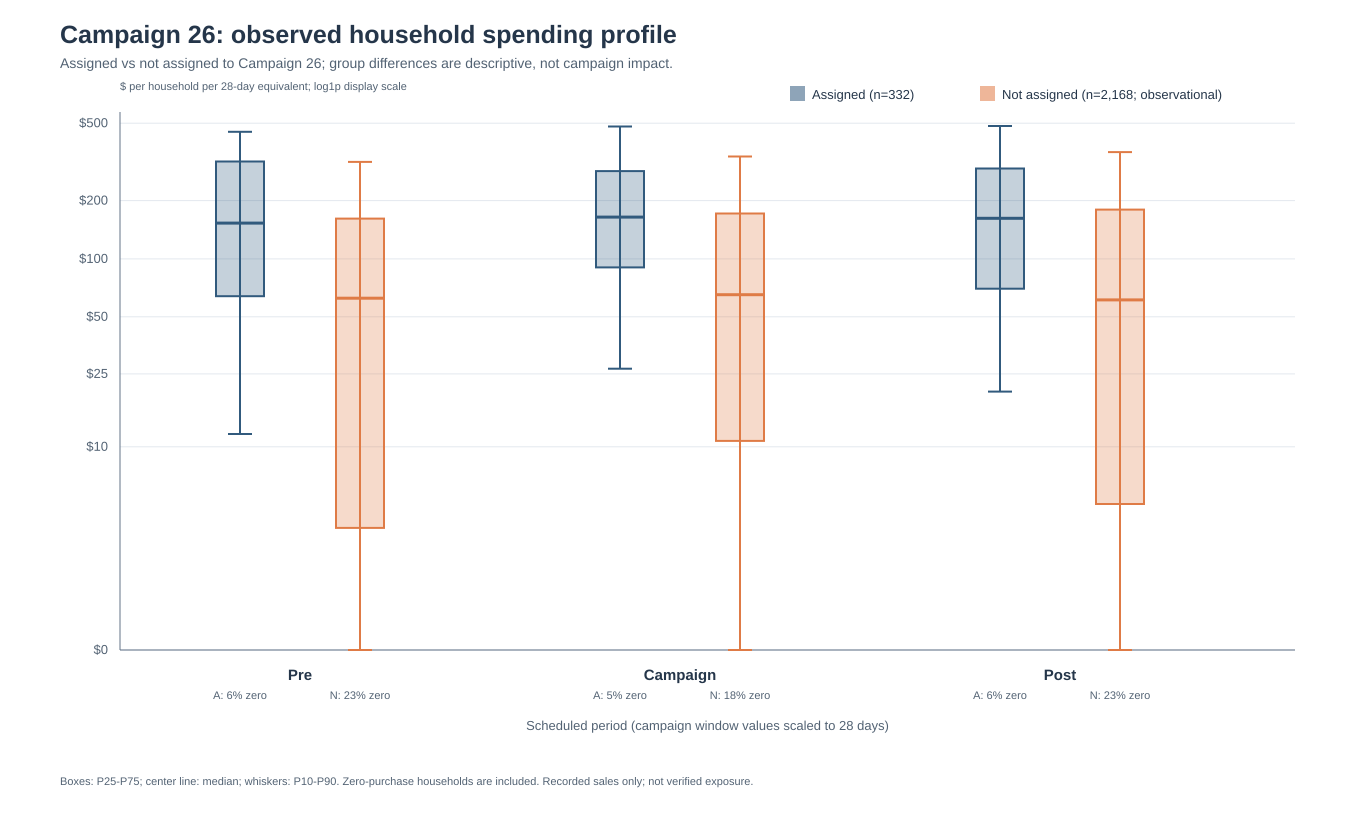

Saved vector chart: docs/figures/campaign26_observed_spending.svg


In [35]:
from IPython.display import SVG,display

phase3_spending_svg=campaign26_spending_svg(
    phase3_c26_household_period,phase3_c26_descriptive_summary
)
phase3_spending_path=save_svg(
    phase3_spending_svg,project_root/'docs'/'figures'/'campaign26_observed_spending.svg'
)
display(SVG(phase3_spending_svg))
print('Saved vector chart:',phase3_spending_path.relative_to(project_root).as_posix())


In [36]:
phase3_promotion_counts=fetch_promotion_quality(engine)
phase3_promotion_key_quality,phase3_promotion_line_quality=summarize_promotion_quality(
    phase3_promotion_counts
)
print('Product-store-week promotion source/mart quality:')
display(phase3_promotion_key_quality)
print('Promotion record match coverage against sales lines:')
display(phase3_promotion_line_quality)


Product-store-week promotion source/mart quality:


,aggregated_product_store_week_keys,source_rows_represented,extra_source_rows_at_repeated_keys,keys_with_multiple_source_rows,keys_with_conflicting_promotion_states,first_promotion_week,last_promotion_week,promotion_weeks
0,36771279,36786524,15245,15245,15245,9,101,93


Promotion record match coverage against sales lines:


,sales_lines,lines_with_promotion_record,lines_without_promotion_record,match_coverage_pct,unmatched_pct,matched_lines_on_conflicting_keys
0,2595732,563774,2031958,21.72,78.28,858


In [37]:
import hashlib
import pandas as pd
from pandas.testing import assert_frame_equal

phase3_expected_spending=pd.DataFrame([
    ['Assigned to Campaign 26','Pre',28,332,313,19,94.3,208.32,208.32,11.79,64.08,153.06,318.00,451.91,7.15,7.15,6.00],
    ['Not assigned to Campaign 26','Pre',28,2168,1659,509,76.5,117.32,117.32,0.00,3.22,62.52,161.47,316.40,4.28,4.28,3.00],
    ['Assigned to Campaign 26','Campaign',41,332,316,16,95.2,323.81,221.14,26.65,90.34,164.50,283.61,480.85,10.53,7.19,5.46],
    ['Not assigned to Campaign 26','Campaign',41,2168,1785,383,82.3,181.29,123.81,0.00,10.80,65.19,171.72,337.15,6.26,4.27,2.73],
    ['Assigned to Campaign 26','Post',28,332,311,21,93.7,216.63,216.63,20.10,70.01,162.19,292.49,483.86,6.97,6.97,5.00],
    ['Not assigned to Campaign 26','Post',28,2168,1666,502,76.8,128.00,128.00,0.00,4.60,61.25,179.88,355.39,4.27,4.27,2.00],
],columns=[
    'assignment_group','period','days','households_including_zeros','active_households',
    'zero_purchase_households','active_rate_pct','mean_spend_actual_window_per_household',
    'mean_spend_per_28d_equivalent','p10_spend_per_28d_equivalent',
    'p25_spend_per_28d_equivalent','p50_spend_per_28d_equivalent',
    'p75_spend_per_28d_equivalent','p90_spend_per_28d_equivalent',
    'mean_baskets_actual_window_per_household','mean_baskets_per_28d_equivalent',
    'median_baskets_per_28d_equivalent'
])
phase3_summary_columns=list(phase3_expected_spending.columns)
phase3_actual_spending=phase3_c26_descriptive_summary[phase3_summary_columns].copy()
assert_frame_equal(phase3_actual_spending,phase3_expected_spending,check_dtype=False,check_exact=True)

assert len(phase3_campaign_overview)==30
assert int(phase3_campaign_overview.recorded_redemption_events.sum())==2318
phase3_c26_check=phase3_campaign_overview.loc[phase3_campaign_overview.campaign_id==26].iloc[0]
assert int(phase3_c26_check.assigned_households)==332
assert int(phase3_c26_check.recorded_redemption_events)==73
assert int(phase3_c26_check.unique_redeemers)==31
assert len(phase3_c26_household_period)==7500
assert verify_readonly(engine)

assert int(phase3_promotion_key_quality.loc[0,'source_rows_represented'])==36786524
assert int(phase3_promotion_key_quality.loc[0,'aggregated_product_store_week_keys'])==36771279
assert int(phase3_promotion_key_quality.loc[0,'keys_with_conflicting_promotion_states'])==15245
assert int(phase3_promotion_line_quality.loc[0,'sales_lines'])==2595732
assert int(phase3_promotion_line_quality.loc[0,'lines_with_promotion_record'])==563774
assert int(phase3_promotion_line_quality.loc[0,'lines_without_promotion_record'])==2031958
assert float(phase3_promotion_line_quality.loc[0,'match_coverage_pct'])==21.72
assert int(phase3_promotion_line_quality.loc[0,'matched_lines_on_conflicting_keys'])==858

phase3_expected_chart_hashes={
    'campaign_assignment_overlap.svg':'9230F574B581A258B79F20B9526F82EECE1D06C97B6003E6DC49B0CE3CE40AA2',
    'campaign26_observed_spending.svg':'B638AB364F27C574E4D52C494ED8D6ECDDD51F8098C99828983FB861B8176728',
}
for filename,expected_hash in phase3_expected_chart_hashes.items():
    actual_hash=hashlib.sha256((project_root/'docs'/'figures'/filename).read_bytes()).hexdigest().upper()
    assert actual_hash==expected_hash,(filename,actual_hash)

print('Descriptive analysis reproducibility checks passed: campaigns=30; redemptions=2,318; Campaign 26=332 assigned, 31 redeemers, 73 events; promotion match=21.72%.')
print('Existing six-window spending summaries and both chart files match the saved descriptive baseline.')


Descriptive analysis reproducibility checks passed: campaigns=30; redemptions=2,318; Campaign 26=332 assigned, 31 redeemers, 73 events; promotion match=21.72%.
Existing six-window spending summaries and both chart files match the saved descriptive baseline.


### Business meaning and limitations

Campaign assignment counts describe the households listed for targeting. Recorded coupon redemptions are separate observed events; they do not count everyone who received or saw a campaign. Exposure is not present in the source tables. “Co-assigned” means that a household has another campaign assignment record; schedule overlap is derived from the campaigns’ relative-day ranges, not the timing of assignment or media delivery.

Campaign 26 spending is recorded transaction value per household, not margin or profit. Window rates include households with zero purchases and normalize the 41-day campaign window to a 28-day equivalent. Differences between periods or assignment groups are descriptive profiles only: the groups are not randomized, other campaigns may overlap, exposure is unknown, and other calendar or customer differences may explain the patterns.

Promotion-record coverage is a product-store-week join. An unmatched transaction line means **promotion status unknown**, not confirmed no promotion. Repeated product-store-week keys with multiple source rows and conflicting codes remain flagged; the code meanings are undocumented and household-level exposure cannot be inferred from them. These limitations rule out incremental-uplift conclusions from this phase.


### Descriptive results readout

The 30 scheduled campaigns range from **33 to 162 days** and have **12 to 1,133 unique assigned households** each. Recorded coupon redemptions range from 1 to 653 events per campaign; these events confirm recorded coupon use only. Campaign 26 is TypeA, runs 41 scheduled days (224-264), has **332 assigned households**, **73 redemption events** and **31 unique redeemers**. Its redemption records are not an exposure count.

For Campaign 26, **313/332 (94.3%)** assigned households also have an assignment to another campaign somewhere in the assignment table. **22/332 (6.6%)** were co-assigned to a campaign whose scheduled dates overlap Campaign 26's own 41-day schedule. The earlier audit's **50** treated households refers to the broader pre/campaign/post evaluation window, which also includes Campaign 29's post-window schedule. These are assignment overlaps, not confirmed concurrent exposure.

| Assignment group | Window | Active households | Zero-purchase households | Mean actual-window spend / household | Mean spend / household / 28-day equivalent | Median spend (P10-P90), 28-day equivalent | Mean baskets / household / 28-day equivalent |
|---|---|---:|---:|---:|---:|---:|---:|
| Assigned to C26 (n=332) | Pre, 28 days | 313 (94.3%) | 19 | $208.32 | $208.32 | $153.06 ($11.79-$451.91) | 7.15 |
| Not assigned to C26 (n=2,168) | Pre, 28 days | 1,659 (76.5%) | 509 | $117.32 | $117.32 | $62.52 ($0.00-$316.40) | 4.28 |
| Assigned to C26 (n=332) | Campaign, 41 days | 316 (95.2%) | 16 | $323.81 | $221.14 | $164.50 ($26.65-$480.85) | 7.19 |
| Not assigned to C26 (n=2,168) | Campaign, 41 days | 1,785 (82.3%) | 383 | $181.29 | $123.81 | $65.19 ($0.00-$337.15) | 4.27 |
| Assigned to C26 (n=332) | Post, 28 days | 311 (93.7%) | 21 | $216.63 | $216.63 | $162.19 ($20.10-$483.86) | 6.97 |
| Not assigned to C26 (n=2,168) | Post, 28 days | 1,666 (76.8%) | 502 | $128.00 | $128.00 | $61.25 ($0.00-$355.39) | 4.27 |

All 2,500 purchasing households are included in each window; zero-purchase households remain at zero in the percentiles and charts. Spending and basket frequency are higher for assigned households even in the pre-period. The non-assigned group is not randomized and includes households assigned to other campaigns, so these differences are descriptive and must not be attributed to Campaign 26.

Promotion records cover relative weeks 9-101 (93 weeks), while the transaction source covers weeks 1-102 (102 weeks). The campaign-promotion join matches **563,774/2,595,732 transaction lines (21.72%)**; **2,031,958 (78.28%) are unmatched**, meaning promotion status is unknown. There are **15,245 extra source rows at repeated product-store-week keys**, and the aggregate flags **15,245 keys with multiple/conflicting source states**; 858 matched sales lines join to conflicting keys. This repeated-key count is not a count of byte-identical rows. Code meanings remain undocumented, so neither matched promotional status nor campaign assignment proves household exposure.
